# CellphoneDB学习手册

 ![CellphoneDB Logo](https://www.cellphonedb.org/images/cellphonedb_logo_33.png) | CellphoneDB是一个公开可用的人类受体、配体及其相互作用的存储库。

In [ ]:
from datetime import date
print("Author: Biomamba_pudding")
print("Date:", date.today())

# 零、欢迎关注**Biomamba 生信基地**

## Biomamba，理学博士，此公众号旨在分享生信知识及科研经验与体会，目前在B站的同名账号中发布的手把手教你做单细胞测序数据分析系列视频点击量已经超过45.8W。同名微信公众号拥有超过五万的关注用户以及超过五百万的访问量。如果需要数据分析指导、生信热点全文复现、自测/数据库数据个性化分析辅导、常态化实验学习，欢迎联系客服微信[Biomamba_yunying]

![./img/Rmarkdown开头2025.jpg](http://biomamba.com:34080/free.download/file.back/biomamba/Rmarkdown%E5%BC%80%E5%A4%B42025.jpg)

# 一、写在前面

## 本教程基于Linux中的jupyter环境演示，计算资源不足的同学可参考：  
[生信分析为什么要使用服务器？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491007&idx=1&sn=8619c2bad23791b3252a1c4cb1831931&chksm=9b3f64efac48edf9c02f84959aeee9b12480736fce70c5ddb8b41d79cfc22ce590ea2cb60fba&token=1760636281&lang=zh_CN#rd)\
[足够支持你完成硕博生涯的生信环境](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511780&idx=1&sn=3acc0874f7d2fa75f1abbe7a9a9b4069&chksm=9b3cd7b4ac4b5ea27d4d53964e4a4a9fa8c806a19103729dd4ff0fa72e621411f46a251d269f&scene=21#wechat_redirect)\
[配置一个心仪的工作站(硬件+环境配置)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519707&idx=1&sn=73dcab26f9b2ed75a954327317d07112&chksm=9b3cf48bac4b7d9df5b5a432fbe70d4f9c13bc8d739aa401732614f022223d1912642a7e4bea&scene=21#wechat_redirect)\
[独享服务器，生信分析不求人](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503618&idx=1&sn=ca47ca985aa8560f6b38f15f210519e2&chksm=9b3cb652ac4b3f44292560071b7e98e2f6fa6ec03581cd882a4d59b9d7fa063a5b9ac1b923f3&scene=21#wechat_redirect)\
[为实验室准备一份生物信息学不动产](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247492383&idx=1&sn=b8d912877cb38e8d8c9084d1d9370ded&chksm=9b3c9a4fac4b135926091a8af972c45a17a2fa1f94c704779c60df5f733847036c3797894c1c&scene=21#wechat_redirect)


## Linux和Conda是我们本次课程环境搭建的基础，这两部分我们在前期推送中也有相关内容介绍。如果还没有接触过的同学可以跟随我们[十小时学会Linux](https://mp.weixin.qq.com/s/77IMXW_6QFLpbqSeMLfNJg)、[生信软件管家——conda的安装、使用、卸载](https://mp.weixin.qq.com/s/VwRHks00awHXY1tfoPNX9A)和[利用conda打包/复刻生信环境](https://mp.weixin.qq.com/s/y_NPTabHSDGPw2D-_Izs1A)教程内容提前学习一下。

## jupyter notebook作为Python的集成环境，可以逐行运行Python代码并返回结果，并且支持markerdown语法编译，可以说是一个学习Python的笔记本。jupyter notebook使用可以参考[码Python神器：jupyter notebook](https://mp.weixin.qq.com/s/bK_Ri16z8YG-1ZyRqkhM9A)。


##  Python作为本次课程**核心编程语言**。它语法简洁、库资源丰富，计算高效，是数据科学、自动化开发等领域的首选，兼顾新手入门与资深者高效需求。因此，同学们在学习这个教程前，需要有一定得Python知识，可以参考[生信Python速查手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499921&idx=1&sn=dcd6f95596e3de9bf378d850c217fe78&chksm=9b3cb9c1ac4b30d7bbd44057b181f87541f5904d24f903494ae557e768ae00c208c1b68b45c7&payreadticket=HFPtvn0Hc_3itk_RHA90ykGyhDmPMGdHlmAWpCN5_JoUcbpyL6P82ctGZm0c2MiiBCZcLU0#rd)进行快速学习

# 二、CellPhoneDB 与空间转录组通讯分析

## 1. CellPhoneDB简介

$\text{CellPhoneDB}$ 是一个广泛应用于单细胞 $\text{RNA}$ 测序 ($\text{scRNA-seq}$) 数据的**细胞间通讯（$\text{Cell-Cell}$ $\text{Communication}$）分析工具**。它的核心是一个综合性的**配体-受体 ($\text{Ligand-Receptor, L-R}$) 数据库**和一套**统计学框架**。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/cpdb.png)

### 1.1 核心功能

1.  **全面数据库**：收录了大量的已验证的配体-受体复合物及其亚基组成。
2.  **通讯推断**：通过将细胞类型（$\text{Cluster}$）的平均基因表达量与数据库进行比对，推断每对细胞类型之间潜在的 $\text{L-R}$ 相互作用强度。
3.  **统计显著性**：使用**非参数排列检验（$\text{Permutation}$ $\text{Test}$）**来确定观察到的 $\text{L-R}$ 相互作用强度是否显著高于随机预期。

### 1.2 传统分析局限

在传统的 $\text{scRNA-seq}$ 分析中，$\text{CellPhoneDB}$ 只能告诉我们**哪两种细胞类型之间可能存在通讯**，但无法确定这种通讯在**组织中的具体位置和距离**。

## 2. CellPhoneDB 在空间转录组中的应用

随着空间转录组 ($\text{ST}$) 技术的发展，$\text{CellPhoneDB}$（或类似 $\text{L-R}$ 分析方法，如 $\text{Squidpy}$ 的 $\text{ligrec}$）被扩展应用，以解决**空间环境下的细胞通讯问题**。

### 2.1 解决的关键问题

空间转录组数据（如 $\text{Visium}$）的优势在于保留了 $\text{Spot}$ 的**物理坐标**，这使得我们可以分析：

* **空间邻近的细胞/Spot 簇**之间的通讯。
* 通讯信号是否沿着特定的**解剖学轴线或微环境边界**传播。

### 2.2 分析流程的调整与集成

由于 $\text{Visium}$ 的 $\text{Spot}$ 是多细胞混合信号，现代 $\text{ST}$ 通讯分析方法通常会**原生集成空间信息**：

| 特性 | 传统 $\text{scRNA-seq}$ ($\text{Cluster}$) | 空间转录组 ($\text{ST}$ $\text{Cluster}$) |
| :--- | :--- | :--- |
| **输入单位** | 细胞类型（$\text{Cluster}$）的表达均值 | 空间 $\text{Spot}$ 簇（$\text{Cluster}$）的表达均值 |
| **空间约束** | 无。所有簇对均推断通讯 | **有。**通常只关注**物理上相邻**的 $\text{Spot}$ 簇对之间的通讯 |
| **工具集成** | $\text{CellPhoneDB}$ 软件 | **$\text{Squidpy.gr.ligrec}$** 或经过空间过滤的 $\text{CellPhoneDB}$ 实现 |

**总结**：将 $\text{CellPhoneDB}$ 的 $\text{L-R}$ 数据库与空间转录组数据相结合，使得研究人员能够将细胞通讯的分子机制精确地定位到组织内的特定微环境中，极大地增强了对复杂组织生物学的理解。

# 三、代码实操

**CellphoneDB method 3 (差异表达)**

在本例中，我们使用方法 3（`degs_analysis_method`）来研究随着滋养层细胞分化并侵入母体子宫，周围血管细胞（PVs）与滋养层细胞之间的细胞间相互作用是如何变化的。这种方法将检索到至少有一个相互作用对（参与相互作用的基因）表现出差异表达的相互作用。

> **差异表达基因应由偏好方法预先计算**（例如 Limma、DEseq2、Seurat、TradeSeq 等），并将显著结果以预定义的表格格式传递给 CellphoneDB。

### 1. 检查版本信息

In [58]:
import pandas as pd
import sys
import os
plt.rcdefaults()

pd.set_option('display.max_columns', 100)
# 设定工作目录
os.chdir('/home/chenao/jupyter_home/downstream/process/neighbor_analysis/cellphonedb')

这里我们的 `python` 环境必须大于3.8

In [ ]:
print(sys.version)

安装最新版本的CellphoneDB（V5）

In [ ]:
# pip install --quiet cellphonedb

___
### 2. 输入文件
标准的 CellphoneDB 统计分析流程（statistial method）需要5个输入文件 (其中3个是必须的).
- **cpdb_file_path**: (必须) 由官方提供的受配体库文件 `cellphonedb.zip`
- **meta_file_path**: (必须) 链接细胞/spot对应barcode和其注释信息（例如细胞类型、样本信息、空间环境信息等） `metadata.tsv`
- **counts_file_path**: (必须) 标准化细胞/spot表达矩阵 Normolized data (非 Z 值矩阵即 scale data), 或者为scanpy生成的 h5ad 文件 (推荐) `normalised_log_counts.h5ad`
- **degs_file_path**: (必须) 指定不同cluster间的差异表达基因，只有那些显著差异表达基因会被涵盖通讯分析
- **microenvs_file_path** (可选) 细胞所在分组或微环境信息. 当提供微环境信息，CellphoneDB分析过程将会严格限制细胞或spot所在同一微环境。
- **active_tf_path**: (可选) 为不同细胞类型提供活跃的转录因子

`microenvs_file_path` & `degs_file_path` 的内容将取决于研究者想要回答的生物问题。

> 在测试文件中，我们研究免疫细胞的子集与滋养层细胞之间的细胞间相互作用如何变化，随着滋养层细胞的分化和侵入母体子宫。该模块将在每个微环境 (`microenvs_file_path`) 内随机打乱所有细胞的聚类标签，进行 1,000 次（默认），以测试某个聚类中的平均受体表达水平和相互作用聚类之间的平均配体表达水平是否高于其他细胞对的水平。此过程生成一个 P 值，用于表示给定受体-配体复合物的细胞类型特异性的可能性。

> CellphoneDB将检索在PVs和滋养层细胞之间发生的所有相互作用，其中：（i）所有蛋白质在相应的细胞类型中表达，以及（ii）至少一个基因在滋养层细胞中差异表达。

In [ ]:
cpdb_file_path = '/data/10_spatial_communication/cellphonedb/data/cellphonedb.zip'
# CellPhoneDB 数据库文件路径：L-R 相互作用数据库。

meta_file_path = '/data/10_spatial_communication/cellphonedb/data/metadata.tsv'
# 元数据文件路径：包含每个 Spot/细胞的分组信息（如细胞类型或聚类）。

counts_file_path = '/data/10_spatial_communication/cellphonedb/data/normalised_log_counts.h5ad'
# 基因表达计数文件路径：用于 CellPhoneDB 计算的标准化和对数转换后的表达矩阵。

degs_file_path = '/data/10_spatial_communication/cellphonedb/data/DEGs_inv_trophoblast.tsv'
# 差异表达基因 (DEGs) 文件路径：用于辅助分析或过滤。

microenvs_file_path = '/data/10_spatial_communication/cellphonedb/data/microenvironment.tsv'
# 微环境定义文件路径：用于定义特定的组织微环境。

active_tf_path = '/data/10_spatial_communication/cellphonedb/data/active_TFs.tsv'
# 活性转录因子 (TFs) 文件路径：用于整合转录调控信息。

out_path = '/data/10_spatial_communication/cellphonedb/results'
# 输出目录路径：所有 CellPhoneDB 结果（如均值、p 值等）的保存位置。

### 3. 检查输入文件

<span style="color:green">**1)**</span>  **metadata** 文件由两列组成:
- **barcode_sample**: 这列数据指定每个细胞或spot的barcode信息。
- **cell_type**: 这列为每个barcode所分配的细胞类型信息（空间转录组可由 `cell2location`或 `tangram`等映射软件处理后获取）。

In [3]:
metadata = pd.read_csv(meta_file_path, sep = '\t')
metadata.head(3)

,barcode_sample,cell_type
0,AGCGATTAGTCTAACC-1_Pla_HDBR10917733,B_cells
1,ATCCGTGAGGCTAGAA-1_Pla_Camb10714918,B_cells
2,AGTAACCCATTAAAGG-1_Pla_HDBR10917733,B_cells


<span style="color:green">**2)**</span>  **counts** 是一个scanpy生成的h5ad文件。该数据的meta信息必须与 `meta`文件所对齐。 (两个文件必须由相同的细胞/spot数)。

In [4]:
import anndata

adata = anndata.read_h5ad(counts_file_path)
adata.obs.head(3)

,n_genes,n_counts,cell_labels
barcode_sample,,,
AGCGATTAGTCTAACC-1_Pla_HDBR10917733,1259.0,3053.0,B_cells
ATCCGTGAGGCTAGAA-1_Pla_Camb10714918,699.0,844.0,B_cells
AGTAACCCATTAAAGG-1_Pla_HDBR10917733,1025.0,2399.0,B_cells


检查metadata和counts文件的barcode信息是否一致

In [6]:
list(adata.obs.index).sort() == list(metadata['barcode_sample']).sort()

True

<span style="color:green">**3)**</span> **Micronevironments** 定义了细胞/spot所属的不同微环境。CellphoneDB仅仅计算同属同一微环境细胞/spot间交互信息。

In [10]:
microenv = pd.read_csv(microenvs_file_path,
                       sep = '\t')
microenv.head(3)

,cell_type,microenvironment
0,PV MMP11,Env1
1,PV MYH11,Env1
2,PV STEAP4,Env1


查看不同细胞/spot所属的微环境

In [11]:
microenv.groupby('microenvironment', group_keys = False)['cell_type'].apply(lambda x : list(x.value_counts().index))

microenvironment
Env1    [PV MMP11, PV MYH11, PV STEAP4, EVT_1, EVT_2, ...
Name: cell_type, dtype: object

<span style="color:green">**4)**</span> **Active transcription factors** 输入不同细胞类型所活跃的转录因子

In [13]:
pd.read_csv(active_tf_path, sep = '\t').head(3) 

,cluster,TF
0,EVT_1,ASCL2
1,EVT_1,ELK3
2,EVT_1,GATA3


<span style="color:green">**3)**</span> **差异表达基因**文件是一个两列的文件，指示哪些基因在某种细胞类型中上调（或特异性）。**第一列**对应于簇名称（这些与元数据文件中的匹配），**第二列**是上调的基因。CellphoneDB会忽略其余列。此文件中存在的所有基因将被考虑，因此必须在此文件中仅提供被认为是上调的或与分析相关的基因。

In [30]:
pd.read_csv(degs_file_path, sep = '\t') \
    .head(3)

,cluster,gene,logFC,P.Value,adj.P.Val
0,GC,BGN,1.605019,3.950450e-131,4.844832e-127
1,GC,HLA-G,1.412923,5.616884e-254,6.888547e-250
2,GC,B2M,1.358709,0.000000e+00,0.000000e+00


____
### 4. 运行统计分析
输出文件将会被存在 `output_path` 并返回之前定义好的变量

In [37]:
from cellphonedb.src.core.methods import cpdb_degs_analysis_method

cpdb_results = cpdb_degs_analysis_method.call(
    cpdb_file_path = cpdb_file_path,                 # 必须：CellphoneDB数据库文件
    meta_file_path = meta_file_path,                 # 必须：tsv文件必须定义细胞/spot的barcodes和细胞标签
    counts_file_path = counts_file_path,             # 必须: 标准化表达矩阵（count文件或h5ad文件）
    counts_data = 'hgnc_symbol',                     # 定义基因注释的类型 (hgnc_symbol, entrez, ensembl)
    active_tfs_file_path = active_tf_path,           # 可选：定义不同细胞类型所活跃的转录因子。
    degs_file_path = degs_file_path,                 # 必选: 差异标记基因
    microenvs_file_path = microenvs_file_path,       # 可选：定义不同细胞/spot所属的微环境
    score_interactions = True,                       # 可选：是否计算interaction scores
    threshold = 0,                                   # 定义在分析中使用该基因所需的细胞表达最小百分比
    threads = 5,                                     # 分析所用线程
    result_precision = 3,                            # 设定结果中小数的精度
    separator = '|',                                 # 设定分隔符
    output_path = out_path,                          # 保存结果文件路径
    output_suffix = None                             # 用定义的字符串替换输出文件中的时间戳（默认值：无）
    )

[ ][CORE][08/09/25-07:26:00][INFO] [Cluster DEGs Analysis] Threshold:0 Precision:3
Reading user files...
The following user files were loaded successfully:
data/normalised_log_counts.h5ad
data/metadata.tsv
data/microenvironment.tsv
data/active_TFs.tsv
data/DEGs_inv_trophoblast.tsv
[ ][CORE][08/09/25-07:26:02][INFO] Running Real Analysis
[ ][CORE][08/09/25-07:26:02][INFO] Limiting cluster combinations using microenvironments
[ ][CORE][08/09/25-07:26:02][INFO] Running DEGs-based Analysis
[ ][CORE][08/09/25-07:26:02][INFO] Building results
[ ][CORE][08/09/25-07:26:04][INFO] Scoring interactions: Filtering genes per cell type..


100%|██████████| 42/42 [00:00<00:00, 436.08it/s]

[ ][CORE][08/09/25-07:26:04][INFO] Scoring interactions: Calculating mean expression of each gene per group/cell type..



100%|██████████| 42/42 [00:00<00:00, 948.80it/s]


[ ][CORE][08/09/25-07:26:05][INFO] Scoring interactions: Calculating scores for all interactions and cell types..


100%|██████████| 81/81 [00:15<00:00,  5.35it/s]


Saved deconvoluted to results/degs_analysis_deconvoluted_09_08_2025_072620.txt
Saved deconvoluted_percents to results/degs_analysis_deconvoluted_percents_09_08_2025_072620.txt
Saved means to results/degs_analysis_means_09_08_2025_072620.txt
Saved relevant_interactions to results/degs_analysis_relevant_interactions_09_08_2025_072620.txt
Saved significant_means to results/degs_analysis_significant_means_09_08_2025_072620.txt
Saved CellSign_active_interactions to results/degs_analysis_CellSign_active_interactions_09_08_2025_072620.txt
Saved CellSign_active_interactions_deconvoluted to results/degs_analysis_CellSign_active_interactions_deconvoluted_09_08_2025_072620.txt
Saved interaction_scores to results/degs_analysis_interaction_scores_09_08_2025_072620.txt


输出结果将会被保存在之前定义的 `cpdb_results` 路径

In [38]:
list(cpdb_results.keys())

['deconvoluted',
 'deconvoluted_percents',
 'means',
 'relevant_interactions',
 'significant_means',
 'CellSign_active_interactions',
 'CellSign_active_interactions_deconvoluted',
 'interaction_scores']

___
### 5. 输出文件信息
大多数输出文件共享通用列：
- **id_cp_interaction**：数据库中存储的每个交互的唯一 CellphoneDB 标识符。
- **interacting_pair**：由“|”分隔的相互作用对的名称。
- **partner A or B**：第一个相互作用受配体 (A) 或第二个 (B) 的标识符。它可以是：UniProt（前缀 simple:）或复杂（前缀 complex:）
- **gene A or B**：第一个相互作用受配体 (A) 或第二个 (B) 的基因标识符。该标识符将取决于输入用户列表。
- **secreted**：如果其中一个受配体是分泌的则为真。
- **Receptor A or B**：如果第一个相互作用受配体 (A) 或第二个 (B) 在我们的数据库中被注释为受体则为真
- **受体 A 或 B**：如果第一个相互作用手配（A）或第二个（B）在我们的数据库中被标注为受体，则为真。 
- **注释策略**：如果该相互作用由 CellphoneDB 开发者注释，则为策划的。否则，为下载该相互作用的数据库名称。 
- **是否整合素**：如果其中一个受配体是整合素，则为真。 
- **方向性**：指示相互作用的方向性及相互作用者的特征。 
- **分类**：相互作用受配体的通路分类。

**Relevant interaction**:
- **cell_a|cell_b**: 是否被判定为显著

In [40]:
cpdb_results['relevant_interactions'].head(2)

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,PV MMP11|EVT_1,PV MMP11|EVT_2,PV MMP11|iEVT,PV MMP11|VCT_CCC,PV MMP11|GC,PV MMP11|eEVT,PV MYH11|EVT_1,PV MYH11|EVT_2,PV MYH11|iEVT,PV MYH11|VCT_CCC,PV MYH11|GC,PV MYH11|eEVT,PV STEAP4|EVT_1,PV STEAP4|EVT_2,PV STEAP4|iEVT,PV STEAP4|VCT_CCC,PV STEAP4|GC,PV STEAP4|eEVT,EVT_1|PV MMP11,EVT_1|PV MYH11,EVT_1|PV STEAP4,EVT_1|EVT_1,EVT_1|EVT_2,EVT_1|iEVT,EVT_1|VCT_CCC,EVT_1|GC,EVT_1|eEVT,EVT_2|PV MMP11,EVT_2|PV MYH11,EVT_2|PV STEAP4,EVT_2|EVT_1,EVT_2|EVT_2,EVT_2|iEVT,EVT_2|VCT_CCC,EVT_2|GC,EVT_2|eEVT,iEVT|PV MMP11,iEVT|PV MYH11,iEVT|PV STEAP4,iEVT|EVT_1,iEVT|EVT_2,iEVT|iEVT,iEVT|VCT_CCC,iEVT|GC,iEVT|eEVT,VCT_CCC|PV MMP11,VCT_CCC|PV MYH11,VCT_CCC|PV STEAP4,VCT_CCC|EVT_1,VCT_CCC|EVT_2,VCT_CCC|iEVT,VCT_CCC|VCT_CCC,VCT_CCC|GC,VCT_CCC|eEVT,GC|PV MMP11,GC|PV MYH11,GC|PV STEAP4,GC|EVT_1,GC|EVT_2,GC|iEVT,GC|VCT_CCC,GC|GC,GC|eEVT,eEVT|PV MMP11,eEVT|PV MYH11,eEVT|PV STEAP4,eEVT|EVT_1,eEVT|EVT_2,eEVT|iEVT,eEVT|VCT_CCC,eEVT|GC,eEVT|eEVT
0,CPI-SC0A2DB962D,CDH1_integrin_a2b1_complex,simple:P12830,complex:integrin_a2b1_complex,CDH1,NaN,False,False,False,curated,True,Adhesion-Adhesion,Adhesion by Cadherin,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,1,0,1,1,0,1,0,0,0,1,0,1,1,0,1,1,0,0,1,1,1,1,1,1,0,0,0,1,0,1,1,0,1,0,0,0,1,0,1,1,0,1,0,0,0,1,0,1,1,0,1
1,CPI-SC0B5CEA47D,COL10A1_integrin_a2b1_complex,simple:Q03692,complex:integrin_a2b1_complex,COL10A1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Collagen/Integrin,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,1


**Significant means**:
- **significant_mean**: 所有相互作用的受配体的显著均值计算。如果发现该交互具有相关性，则该值将为均值。否则，该值将缺失。

In [ ]:
cpdb_results['significant_means'].head(2)

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,rank,PV MMP11|PV MMP11,PV MMP11|PV MYH11,PV MMP11|PV STEAP4,PV MMP11|EVT_1,PV MMP11|EVT_2,PV MMP11|iEVT,PV MMP11|VCT_CCC,PV MMP11|GC,PV MMP11|eEVT,PV MYH11|PV MMP11,PV MYH11|PV MYH11,PV MYH11|PV STEAP4,PV MYH11|EVT_1,PV MYH11|EVT_2,PV MYH11|iEVT,PV MYH11|VCT_CCC,PV MYH11|GC,PV MYH11|eEVT,PV STEAP4|PV MMP11,PV STEAP4|PV MYH11,PV STEAP4|PV STEAP4,PV STEAP4|EVT_1,PV STEAP4|EVT_2,PV STEAP4|iEVT,PV STEAP4|VCT_CCC,PV STEAP4|GC,PV STEAP4|eEVT,EVT_1|PV MMP11,EVT_1|PV MYH11,EVT_1|PV STEAP4,EVT_1|EVT_1,EVT_1|EVT_2,EVT_1|iEVT,EVT_1|VCT_CCC,EVT_1|GC,EVT_1|eEVT,EVT_2|PV MMP11,EVT_2|PV MYH11,EVT_2|PV STEAP4,EVT_2|EVT_1,EVT_2|EVT_2,EVT_2|iEVT,EVT_2|VCT_CCC,EVT_2|GC,EVT_2|eEVT,iEVT|PV MMP11,iEVT|PV MYH11,iEVT|PV STEAP4,iEVT|EVT_1,iEVT|EVT_2,iEVT|iEVT,iEVT|VCT_CCC,iEVT|GC,iEVT|eEVT,VCT_CCC|PV MMP11,VCT_CCC|PV MYH11,VCT_CCC|PV STEAP4,VCT_CCC|EVT_1,VCT_CCC|EVT_2,VCT_CCC|iEVT,VCT_CCC|VCT_CCC,VCT_CCC|GC,VCT_CCC|eEVT,GC|PV MMP11,GC|PV MYH11,GC|PV STEAP4,GC|EVT_1,GC|EVT_2,GC|iEVT,GC|VCT_CCC,GC|GC,GC|eEVT,eEVT|PV MMP11,eEVT|PV MYH11,eEVT|PV STEAP4,eEVT|EVT_1,eEVT|EVT_2,eEVT|iEVT,eEVT|VCT_CCC,eEVT|GC,eEVT|eEVT
1081,CPI-CC06080894C,GABA_byGAD2_and_SLC6A11_GABA-A_a1b3g2S_complex,complex:GABA_byGAD2_and_SLC6A11,complex:GABA-A_a1b3g2S_complex,NaN,NaN,True,False,True,curated,False,Ligand-Receptor,Signaling by GABA,0.012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.012
2829,CPI-SS0DC001A77,INHBC_ACVR2A,simple:P55103,simple:P27037,INHBC,ACVR2A,True,False,True,curated,False,Ligand-Receptor,Signaling by Inhibin/Activin,0.012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.076


**Means** :
- **means**: 所有交互受配体的均值：均值指的是相应交互细胞类型对中每个个体受配体平均表达值的总平均值。如果其中一个均值为0，则总平均值设定为0。

In [42]:
cpdb_results['means'].head(2)

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,PV MMP11|PV MMP11,PV MMP11|PV MYH11,PV MMP11|PV STEAP4,PV MMP11|EVT_1,PV MMP11|EVT_2,PV MMP11|iEVT,PV MMP11|VCT_CCC,PV MMP11|GC,PV MMP11|eEVT,PV MYH11|PV MMP11,PV MYH11|PV MYH11,PV MYH11|PV STEAP4,PV MYH11|EVT_1,PV MYH11|EVT_2,PV MYH11|iEVT,PV MYH11|VCT_CCC,PV MYH11|GC,PV MYH11|eEVT,PV STEAP4|PV MMP11,PV STEAP4|PV MYH11,PV STEAP4|PV STEAP4,PV STEAP4|EVT_1,PV STEAP4|EVT_2,PV STEAP4|iEVT,PV STEAP4|VCT_CCC,PV STEAP4|GC,PV STEAP4|eEVT,EVT_1|PV MMP11,EVT_1|PV MYH11,EVT_1|PV STEAP4,EVT_1|EVT_1,EVT_1|EVT_2,EVT_1|iEVT,EVT_1|VCT_CCC,EVT_1|GC,EVT_1|eEVT,EVT_2|PV MMP11,EVT_2|PV MYH11,EVT_2|PV STEAP4,EVT_2|EVT_1,EVT_2|EVT_2,EVT_2|iEVT,EVT_2|VCT_CCC,EVT_2|GC,EVT_2|eEVT,iEVT|PV MMP11,iEVT|PV MYH11,iEVT|PV STEAP4,iEVT|EVT_1,iEVT|EVT_2,iEVT|iEVT,iEVT|VCT_CCC,iEVT|GC,iEVT|eEVT,VCT_CCC|PV MMP11,VCT_CCC|PV MYH11,VCT_CCC|PV STEAP4,VCT_CCC|EVT_1,VCT_CCC|EVT_2,VCT_CCC|iEVT,VCT_CCC|VCT_CCC,VCT_CCC|GC,VCT_CCC|eEVT,GC|PV MMP11,GC|PV MYH11,GC|PV STEAP4,GC|EVT_1,GC|EVT_2,GC|iEVT,GC|VCT_CCC,GC|GC,GC|eEVT,eEVT|PV MMP11,eEVT|PV MYH11,eEVT|PV STEAP4,eEVT|EVT_1,eEVT|EVT_2,eEVT|iEVT,eEVT|VCT_CCC,eEVT|GC,eEVT|eEVT
0,CPI-SC0A2DB962D,CDH1_integrin_a2b1_complex,simple:P12830,complex:integrin_a2b1_complex,CDH1,NaN,False,False,False,curated,True,Adhesion-Adhesion,Adhesion by Cadherin,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.105,0.0,0.0,0.071,0.099,0.089,0.077,0.099,0.346,0.077,0.0,0.0,0.043,0.071,0.060,0.048,0.070,0.317,0.131,0.0,0.0,0.097,0.125,0.115,0.102,0.124,0.371,0.194,0.0,0.0,0.160,0.188,0.177,0.165,0.187,0.434,0.321,0.0,0.0,0.287,0.315,0.305,0.292,0.314,0.561,0.193,0.0,0.0,0.159,0.187,0.177,0.164,0.186,0.433,0.232,0.0,0.0,0.198,0.225,0.215,0.203,0.225,0.472
1,CPI-SC0B5CEA47D,COL10A1_integrin_a2b1_complex,simple:Q03692,complex:integrin_a2b1_complex,COL10A1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Collagen/Integrin,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.041,0.0,0.0,0.006,0.034,0.024,0.012,0.034,0.281,0.000,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.043,0.0,0.0,0.009,0.037,0.026,0.014,0.036,0.283,0.042,0.0,0.0,0.007,0.035,0.025,0.013,0.035,0.282,0.000,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.049,0.0,0.0,0.015,0.043,0.032,0.020,0.042,0.289


**Interaction scores** :
- **scores**: 该值处于0-100之间。值越高，交互更加具有特异性。

In [19]:
cpdb_results['interaction_scores'].head(2)

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,PV MMP11|PV MMP11,PV MMP11|PV MYH11,PV MMP11|PV STEAP4,PV MMP11|EVT_1,PV MMP11|EVT_2,PV MMP11|iEVT,PV MMP11|VCT_CCC,PV MMP11|GC,PV MMP11|eEVT,PV MYH11|PV MMP11,PV MYH11|PV MYH11,PV MYH11|PV STEAP4,PV MYH11|EVT_1,PV MYH11|EVT_2,PV MYH11|iEVT,PV MYH11|VCT_CCC,PV MYH11|GC,PV MYH11|eEVT,PV STEAP4|PV MMP11,PV STEAP4|PV MYH11,PV STEAP4|PV STEAP4,PV STEAP4|EVT_1,PV STEAP4|EVT_2,PV STEAP4|iEVT,PV STEAP4|VCT_CCC,PV STEAP4|GC,PV STEAP4|eEVT,EVT_1|PV MMP11,EVT_1|PV MYH11,EVT_1|PV STEAP4,EVT_1|EVT_1,EVT_1|EVT_2,EVT_1|iEVT,EVT_1|VCT_CCC,EVT_1|GC,EVT_1|eEVT,EVT_2|PV MMP11,EVT_2|PV MYH11,EVT_2|PV STEAP4,EVT_2|EVT_1,EVT_2|EVT_2,EVT_2|iEVT,EVT_2|VCT_CCC,EVT_2|GC,EVT_2|eEVT,iEVT|PV MMP11,iEVT|PV MYH11,iEVT|PV STEAP4,iEVT|EVT_1,iEVT|EVT_2,iEVT|iEVT,iEVT|VCT_CCC,iEVT|GC,iEVT|eEVT,VCT_CCC|PV MMP11,VCT_CCC|PV MYH11,VCT_CCC|PV STEAP4,VCT_CCC|EVT_1,VCT_CCC|EVT_2,VCT_CCC|iEVT,VCT_CCC|VCT_CCC,VCT_CCC|GC,VCT_CCC|eEVT,GC|PV MMP11,GC|PV MYH11,GC|PV STEAP4,GC|EVT_1,GC|EVT_2,GC|iEVT,GC|VCT_CCC,GC|GC,GC|eEVT,eEVT|PV MMP11,eEVT|PV MYH11,eEVT|PV STEAP4,eEVT|EVT_1,eEVT|EVT_2,eEVT|iEVT,eEVT|VCT_CCC,eEVT|GC,eEVT|eEVT
0,CPI-SC0A2DB962D,CDH1_integrin_a2b1_complex,simple:P12830,complex:integrin_a2b1_complex,CDH1,NaN,False,False,False,curated,True,Adhesion-Adhesion,Adhesion by Cadherin,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.851,0.0,0.0,1.098,5.279,4.451,2.003,5.376,18.346,3.458,0.0,0.0,0.649,3.120,2.631,1.184,3.178,10.843,8.003,0.0,0.0,1.502,7.221,6.088,2.74,7.354,25.095,13.246,0.0,0.0,2.485,11.951,10.076,4.536,12.172,41.533,23.891,0.0,0.0,4.482,21.555,18.173,8.181,21.953,74.911,13.188,0.0,0.0,2.474,11.898,10.031,4.516,12.118,41.35,16.390,0.0,0.0,3.075,14.787,12.467,5.612,15.061,51.391
1,CPI-SC0B5CEA47D,COL10A1_integrin_a2b1_complex,simple:Q03692,complex:integrin_a2b1_complex,COL10A1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Collagen/Integrin,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,6.616,0.0,0.0,1.241,5.969,5.033,2.266,6.080,20.746,0.000,0.0,0.0,0.000,0.000,0.000,0.00,0.000,0.000,9.360,0.0,0.0,1.756,8.445,7.120,3.205,8.601,29.349,7.931,0.0,0.0,1.488,7.155,6.032,2.715,7.287,24.866,0.000,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.00,17.304,0.0,0.0,3.246,15.612,13.162,5.925,15.900,54.256


**CellSign** :
- **interacting_pair**: 交互受配体对名称
- **partner A or B**: 第一个交互受配体（A）或第二个（B）的标识符。它可以是：UniProt（前缀 simple:）或复杂的（前缀 complex:）
- **gene A or B**: 第一个交互受配体（A）或第二个互作受配体（B）的基因标识符。该标识符将取决于输入
- **Receptor A or B**: 如果受配体存在于数据库中则为真
- **TF relationship**: 1 表示受体下游的 TF 是活跃的

In [20]:
cpdb_results['CellSign_active_interactions'].head(2)

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,rank,PV MMP11|PV MMP11,PV MMP11|PV MYH11,PV MMP11|PV STEAP4,PV MMP11|EVT_1,PV MMP11|EVT_2,PV MMP11|iEVT,PV MMP11|VCT_CCC,PV MMP11|GC,PV MMP11|eEVT,PV MYH11|PV MMP11,PV MYH11|PV MYH11,PV MYH11|PV STEAP4,PV MYH11|EVT_1,PV MYH11|EVT_2,PV MYH11|iEVT,PV MYH11|VCT_CCC,PV MYH11|GC,PV MYH11|eEVT,PV STEAP4|PV MMP11,PV STEAP4|PV MYH11,PV STEAP4|PV STEAP4,PV STEAP4|EVT_1,PV STEAP4|EVT_2,PV STEAP4|iEVT,PV STEAP4|VCT_CCC,PV STEAP4|GC,PV STEAP4|eEVT,EVT_1|PV MMP11,EVT_1|PV MYH11,EVT_1|PV STEAP4,EVT_1|EVT_1,EVT_1|EVT_2,EVT_1|iEVT,EVT_1|VCT_CCC,EVT_1|GC,EVT_1|eEVT,EVT_2|PV MMP11,EVT_2|PV MYH11,EVT_2|PV STEAP4,EVT_2|EVT_1,EVT_2|EVT_2,EVT_2|iEVT,EVT_2|VCT_CCC,EVT_2|GC,EVT_2|eEVT,iEVT|PV MMP11,iEVT|PV MYH11,iEVT|PV STEAP4,iEVT|EVT_1,iEVT|EVT_2,iEVT|iEVT,iEVT|VCT_CCC,iEVT|GC,iEVT|eEVT,VCT_CCC|PV MMP11,VCT_CCC|PV MYH11,VCT_CCC|PV STEAP4,VCT_CCC|EVT_1,VCT_CCC|EVT_2,VCT_CCC|iEVT,VCT_CCC|VCT_CCC,VCT_CCC|GC,VCT_CCC|eEVT,GC|PV MMP11,GC|PV MYH11,GC|PV STEAP4,GC|EVT_1,GC|EVT_2,GC|iEVT,GC|VCT_CCC,GC|GC,GC|eEVT,eEVT|PV MMP11,eEVT|PV MYH11,eEVT|PV STEAP4,eEVT|EVT_1,eEVT|EVT_2,eEVT|iEVT,eEVT|VCT_CCC,eEVT|GC,eEVT|eEVT
0,CPI-SS0CC966B71,BTC_EGFR,simple:P35070,simple:P00533,BTC,EGFR,True,False,True,curated,False,Ligand-Receptor,Signaling by Epidermal growth factor,0.062,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,CPI-SS060790CF0,EPGN_EGFR,simple:Q6UW88,simple:P00533,EPGN,EGFR,True,False,True,curated,False,Ligand-Receptor,Signaling by Epidermal growth factor,0.111,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0


**Deconvoluted** :
- **gene_name**: 参与“means.csv”文件中定义的相互作用的某个亚单位的基因标识符，标识符将取决于用户列表的输入。
- **uniprot**: 参与“means.csv”文件中定义的相互作用的某个亚单位的 UniProt 标识符
- **is_complex**: 如果亚单位是复合物的一部分则为真。如果不是则为单一，若是则为复合物
- **protein_name**: 参与“means.csv”文件中定义的相互作用的某个亚单位的蛋白质名称
- **complex_name**: 如果亚单位是复合物的一部分，则复合物名称；如果不是则为空
- **mean**: 每个集群中相应基因的平均表达

In [21]:
cpdb_results['deconvoluted'].head(2)

,gene_name,uniprot,is_complex,protein_name,complex_name,id_cp_interaction,gene,B_cells,DC,EVT_1,EVT_2,Endo_F,Endo_L,Endo_M,GC,Granulocytes,HOFB,ILC3,M3,MO,NK,PV MMP11,PV MYH11,PV STEAP4,Plasma,SCT,T_cells,VCT,VCT_CCC,VCT_fusing,VCT_p,dDC,dEpi_lumenal,dEpi_secretory,dM1,dM2,dNK1,dNK2,dNK3,dS1,dS2,dS3,dT_cells,dT_regs,eEVT,fF1,fF2,iEVT,uSMC
multidata_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1355,UBASH3B,Q8TF42,True,UBS3B_HUMAN,Dehydroepiandrosterone_bySTS,CPI-CS09B8977D7,UBASH3B,0.24,0.0,0.621,1.06,0.105,0.212,0.216,1.424,0.0,0.411,0.25,0.465,0.068,0.127,0.114,0.0,0.0,0.0,0.161,0.0,0.484,0.576,0.158,0.454,0.608,0.0,0.124,0.24,0.36,1.134,0.632,0.437,0.118,0.224,0.162,0.025,0.124,1.182,0.055,0.0,1.402,0.338
1355,UBASH3B,Q8TF42,True,UBS3B_HUMAN,Dehydroepiandrosterone_bySTS,CPI-CS05760BB78,UBASH3B,0.24,0.0,0.621,1.06,0.105,0.212,0.216,1.424,0.0,0.411,0.25,0.465,0.068,0.127,0.114,0.0,0.0,0.0,0.161,0.0,0.484,0.576,0.158,0.454,0.608,0.0,0.124,0.24,0.36,1.134,0.632,0.437,0.118,0.224,0.162,0.025,0.124,1.182,0.055,0.0,1.402,0.338


**CellSign** :
- **interacting_pair**: 受配体对的名称
- **partner A or B**:第一个受配体对（A）或第二个（B）的标识符。可以是：UniProt（前缀简单:) 或复合物（前缀复杂:）
- **gene A or B**: 第一个受配体对（A）或第二个（B）的基因标识符。标识符将取决于输入的用户列表
- **Receptor A or B**: 如果第一个受配体对（A）或第二个（B）在我们的数据库中被注释为受体，则为真
- **TF relationship**: 1 表示受体下游的 TF 是活跃的

### 6. 解释 CellphoneDB 结果

该模块允许通过指定：细胞类型对、基因或特定相互作用来过滤CellphoneDB结果

我们可以指定两种细胞类型列表（`query_cell_type_1`和`query_cell_type_2`），该方法将在每个列表中定义的细胞类型之间进行成对比较，并将相互作用子集限制为这些细胞对。每个列表中的细胞类型不会被配对。如果我们有兴趣过滤特定细胞与数据集中所有其他细胞之间发生的相互作用，我们可以定义`query_cell_type_1 = 'All'`和`query_cell_type_2 = ['cellA', 'cellB', ...]`。参数`genes`允许过滤基因参与的相互作用，还可以根据相互作用名称定义特定相互作用`query_interactions`。

> 在**这个例子**中，我们将过滤出滋养层细胞与血管内皮细胞之间的相互作用。此外，我们将选择那些与基因TGFBR1参与的相互作用，以及一个特定的相互作用，名为CSF1_CSF1R。

此方法过滤显著均值文件的行和列；NaN值对应于未显著的交互对，非NaN值对应于被认为相关的交互对。

In [44]:
from cellphonedb.utils import search_utils

search_results = search_utils.search_analysis_results(
    query_cell_types_1 = ['EVT_1', 'EVT_2', 'GC', 'eEVT', 'iEVT'],   # 选择cells 1, 将会与cells2 进行配对(自定义 or 'All'为".").
    query_cell_types_2 = ['PV MMP11', 'PV MYH11', 'PV STEAP4'],     # 选择cells 2, 将会与cells1 进行配对(自定义 or 'All'为".").
    query_genes = ['TGFBR1'],                                       # 根据参与的基因（列表）过滤交互作用
    query_interactions = ['CSF1_CSF1R'],                            # 根据受配体对名称（列表）过滤交互作用
    significant_means = cpdb_results['significant_means'],          # significant_means 文件由 CellphoneDB 生成
    deconvoluted = cpdb_results['deconvoluted'],                    # devonvoluted 文件由 CellphoneDB 生成
    separator = '|',                                                # 分隔符
    long_format = True,                                             # 转化为宽格式，并过滤掉非显著的交互作用
    query_classifications = ['Signaling by Transforming growth factor']
)

search_results.head(3)

,interacting_pair,partner_a,partner_b,gene_a,gene_b,directionality,classification,interacting_cells,significant_mean
0,TGFB3_TGFbeta_receptor2,simple:P10600,complex:TGFbeta_receptor2,TGFB3,NaN,Ligand-Receptor,Signaling by Transforming growth factor,PV MMP11|EVT_1,0.220
3,CSF1_CSF1R,simple:P09603,simple:P07333,CSF1,CSF1R,Ligand-Receptor,Signaling by Colony-Stimulating factor,PV MMP11|EVT_1,0.187
4,TGFB3_TGFbeta_receptor1,simple:P10600,complex:TGFbeta_receptor1,TGFB3,NaN,Ligand-Receptor,Signaling by Transforming growth factor,PV MMP11|EVT_1,0.249


### 7. 基础结果可视化
在本教程的这一部分，我们将利用Kelvin的实现（[kt-plots教程](https://ktplotspy.readthedocs.io/en/latest/index.html)）对从CellphoneDB获得的结果进行一些探索性分析。熟悉数据的生物学背景对于从CellphoneDB结果中获得有意义的结果至关重要。

细胞间相互作用数据可以通过多种方式绘制；弦图/热图描述了在细胞对之间找到的相关相互作用的数量，或者点图表示具体的合作伙伴和相互作用细胞等。

In [ ]:
import os                      # 导入 os 模块，用于操作系统接口操作（如文件路径处理）
import anndata as ad           # 导入 anndata，核心数据结构，用于存储和操作单细胞/空间数据
import pandas as pd            # 导入 Pandas，用于数据结构（DataFrame, Series）操作和管理
import ktplotspy as kpy        # 导入 ktplotspy，通常用于可视化分子网络或细胞通讯结果（如 CellPhoneDB 的结果）
import matplotlib.pyplot as plt# 导入 Matplotlib 的绘图模块

首先，我们将 `relevant_interactions` 和 `means` 的结果转换为一个长表，因为这更方便进行操作，并且这是大多数绘图库的输入格式。

In [ ]:
# -- 获取注释列和相互作用列 -- 

annotation = list(cpdb_results['relevant_interactions'].columns[:13])
# 注释列 (annotation)：
# 从 cpdb_results 字典中提取 'relevant_interactions' DataFrame 的所有列名
# 使用 [:13] 选择前 13 列
# 目的：这些列通常包含描述相互作用的基本信息，如：
#   - 配体/受体名称、基因名称、Ensembl ID、配体亚基、受体亚基、是否是复合体、来源/靶标细胞类型等。

interaction = list(cpdb_results['relevant_interactions'].columns[13:])
# 相互作用列 (interaction)：
# 使用 [13:] 选择从第 13 列开始到末尾的所有列名
# 目的：这些列通常是相互作用的**统计结果**或**定量值**，例如：
#   - p_value 列（显著性）
#   - mean 列（平均表达强度）
#   - 细胞类型对之间的相互作用得分列（e.g., 'Cluster1|Cluster2'）

In [ ]:
# -- 将 relevant_interactions 文件转换为长表 --
relevant_interactions_long = pd.melt(
    cpdb_results['relevant_interactions'],
    # 输入数据：CellPhoneDB 结果中的 'relevant_interactions' DataFrame (宽表)
    id_vars = annotation,
    # 标识符变量 (ID Variables)：保持不变的列（即前面提取的注释信息，如配体/受体名称）
    var_name = 'Interacting_cell',
    # 变量名 (Variable Name)：将原先作为列名的细胞对（如 'Cluster1|Cluster2'）转换成新的一列，并命名为 'Interacting_cell'
    value_vars = interaction,
    # 值变量 (Value Variables)：指定要熔化（从列转为行）的列（即前面提取的相互作用统计值，如均值或 p_value）
    value_name = 'Relevance'
    # 值名称 (Value Name)：将原先在交互列下的值（统计得分/p值）转换成新的一列，并命名为 'Relevance'
)
# 作用：将原本宽格式的相互作用矩阵（每对细胞作为一列）转换为长格式，每行代表一个配体-受体对与一个细胞对之间的特定交互得分。

# -- 拆分交互细胞对列 --
relevant_interactions_long[['Cell_a', 'Cell_b']] = relevant_interactions_long['Interacting_cell'] \
    .str.split('|', expand = True) \
    .rename(columns={0 : 'Cell_a', 1: 'Cell_b'})
# 1. 选择 'Interacting_cell' 列
# 2. 使用 '|' 符号将单元格对字符串（例如 'Cell1|Cell2'）拆分为两列
# 3. expand=True：将拆分结果作为新的 DataFrame 返回
# 4. rename：将拆分后的两列分别命名为 'Cell_a' 和 'Cell_b'
# 5. 将新拆分的这两列赋值回 relevant_interactions_long DataFrame
# 目的：将抽象的相互作用对拆分成明确的发送方和接收方细胞类型列，方便后续过滤和可视化

relevant_interactions_long.head(3)
# 打印转换后的长格式 DataFrame 的前 3 行，用于快速检查数据结构

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,Interacting_cell,Relevance,Cell_a,Cell_b
0,CPI-SC0A2DB962D,CDH1_integrin_a2b1_complex,simple:P12830,complex:integrin_a2b1_complex,CDH1,NaN,False,False,False,curated,True,Adhesion-Adhesion,Adhesion by Cadherin,PV MMP11|EVT_1,0,PV MMP11,EVT_1
1,CPI-SC0B5CEA47D,COL10A1_integrin_a2b1_complex,simple:Q03692,complex:integrin_a2b1_complex,COL10A1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Collagen/Integrin,PV MMP11|EVT_1,0,PV MMP11,EVT_1
2,CPI-SC0C8B7BCBB,COL11A1_integrin_a2b1_complex,simple:P12107,complex:integrin_a2b1_complex,COL11A1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Collagen/Integrin,PV MMP11|EVT_1,0,PV MMP11,EVT_1


In [ ]:
# -- 将 means 文件转换为长表 --
means_long = pd.melt(
    cpdb_results['means'],
    # 输入数据：CellPhoneDB 结果中的 'means' DataFrame (宽表)
    # 目的：该 DataFrame 存储了每对细胞类型/Spot 簇之间，每个 L-R 对的平均表达值
    id_vars = annotation,
    # 标识符变量 (ID Variables)：保持不变的列（即 L-R 对的注释信息，如基因名称、复合体信息等）
    var_name = 'Interacting_cell',
    # 变量名 (Variable Name)：将原先作为列名的细胞对（如 'ClusterA|ClusterB'）转换成新的一列，并命名为 'Interacting_cell'
    value_vars = interaction,
    # 值变量 (Value Variables)：指定要熔化（从列转为行）的列（即所有的细胞对列）
    value_name = 'Mean'
    # 值名称 (Value Name)：将原先在交互列下的值（平均表达值）转换成新的一列，并命名为 'Mean'
)
# 作用：
# 1. 结构转换：将原本宽格式的 L-R 相互作用强度矩阵转换为长格式
# 2. 增强可读性：每行代表一个单一的 L-R 对、一个单一的细胞对以及它们之间特定的平均表达强度值

means_long.head(3)
# 打印转换后的长格式 DataFrame 的前 3 行，用于快速检查数据结构

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,Interacting_cell,Mean
0,CPI-SC0A2DB962D,CDH1_integrin_a2b1_complex,simple:P12830,complex:integrin_a2b1_complex,CDH1,NaN,False,False,False,curated,True,Adhesion-Adhesion,Adhesion by Cadherin,PV MMP11|EVT_1,0.0
1,CPI-SC0B5CEA47D,COL10A1_integrin_a2b1_complex,simple:Q03692,complex:integrin_a2b1_complex,COL10A1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Collagen/Integrin,PV MMP11|EVT_1,0.0
2,CPI-SC0C8B7BCBB,COL11A1_integrin_a2b1_complex,simple:P12107,complex:integrin_a2b1_complex,COL11A1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Collagen/Integrin,PV MMP11|EVT_1,0.0


#### 7.1 按递归排序

为了便于选择感兴趣的相互作用，我们将计算每种相互作用的重复性（即在所有相互作用对中，相互作用被认为是相关的次数）。在这里，假设我们对特定的相互作用感兴趣（即在有限数量的细胞之间发现的相互作用）。这个表格借助先前的知识，以及与其他数据集（如 visium、成像等）的确认，用于选择/验证最相关的相互作用。

In [ ]:
# -- 创建一个字典，记录任何给定交互的相关性重现 --
id_cp_dict = relevant_interactions_long.groupby('id_cp_interaction')['Relevance'] \
    .sum() \
    # 1. 分组求和：根据唯一的配体-受体对 ID ('id_cp_interaction') 进行分组
    # 2. 对每个 L-R 对，求和其在所有细胞对之间的 'Relevance' 值（即相互作用得分或统计值）
    # 目的：计算一个 L-R 对在整个系统中的总体“活跃度”或“重现总和”
    .to_dict()
    # 3. 转换为字典：将结果转换为 {id_cp_interaction: Relevance_Sum} 字典。

# -- 添加新列以指示交互的重复性 --
relevant_interactions_long['Recurrence'] = relevant_interactions_long['id_cp_interaction'] \
    .map(id_cp_dict)
    # 映射：使用上一步创建的字典，将每个 L-R 对的总重现得分映射回长表中的新列 'Recurrence'
    
# -- 根据相关性重现排序 --
relevant_interactions_long = relevant_interactions_long.sort_values(
    ['Recurrence'],
    ascending = True
)
# 排序：根据新创建的 'Recurrence'（重现得分）列对整个长表进行升序排序
# 目的：将整体活跃度最低的 L-R 相互作用排在最前面

relevant_interactions_long.head(3)
# 打印排序后的长格式 DataFrame 的前 3 行，用于快速检查结果

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,Interacting_cell,Relevance,Cell_a,Cell_b,Recurrence
41640,CPI-CS08E678B9D,ProstaglandinE2_byPTGES2_PTGER4,complex:ProstaglandinE2_byPTGES2,simple:P35408,NaN,PTGER4,True,False,True,curated,False,Ligand-Receptor,Signaling by Prostaglandin,VCT_CCC|PV MYH11,0,VCT_CCC,PV MYH11,1
64006,CPI-SC0BAD0A831,WNT7A_FZD4_LRP5,simple:O00755,complex:FZD4_LRP5,WNT7A,NaN,True,False,False,curated,False,Ligand-Receptor,Signaling by WNT,eEVT|eEVT,0,eEVT,eEVT,1
64010,CPI-SC0FBD05A5F,WNT2B_FZD5_LRP5,simple:Q93097,complex:FZD5_LRP5,WNT2B,NaN,True,False,False,curated,False,Ligand-Receptor,Signaling by WNT,eEVT|eEVT,0,eEVT,eEVT,1


基于已有的知识和与实验数据的核实，我们选择了一组具有以下ID的相互作用。

In [ ]:
# -- 选择一些交互进行可视化 --
interactions_to_plot = ['CPI-SC0F36DD437', 'CPI-SC06C3BA86F', 'CPI-SS0AB1F04A0', 'CPI-SC051FC855D', 'CPI-SC0DABCC4B5']

# 过滤：创建一个布尔索引列表，标记哪些行的 'id_cp_interaction' 在指定的交互列表中
idx = [ id in interactions_to_plot for id in relevant_interactions_long['id_cp_interaction'] ]
relevant_interactions_plot = relevant_interactions_long[idx].copy()

现在我们将之前修改为长格式的`means`表中相互作用伙伴的均值表达添加进来。由于不同相互作用对的均值不能直接与其他相互作用对的值进行比较，我们建议在每个相互作用内进行归一化。在这种情况下，我们应用 Z 归一化

In [ ]:
from scipy.stats import zscore

relevant_interactions_plot = relevant_interactions_plot.merge(
    means_long[['id_cp_interaction', 'Interacting_cell', 'Mean']],
    # 右侧 (Right) DataFrame：选择 'means_long' 中的三个关键列：
    # 1. 'id_cp_interaction'：唯一的配体-受体对 ID
    # 2. 'Interacting_cell'：细胞对（如 'ClusterA|ClusterB'）
    # 3. 'Mean'：该 L-R 对在特定细胞对中的平均表达值
    on = ['id_cp_interaction', 'Interacting_cell'],
    # 合并键 (Keys)：指定使用 'id_cp_interaction' 和 'Interacting_cell' 这两列作为连接键
    # 目的：确保只有当 L-R 对和细胞对都相同时，才进行合并
    how = 'inner'
    # 合并类型 (Type)：使用 'inner' 合并
    # 目的：只保留在两个 DataFrame 中都存在匹配键的行
)
# 作用：将每个 L-R 对在特定细胞对中的平均表达强度（'Mean' 值）作为新列，精确地添加或合并到用于绘图的相互作用数据框 relevant_interactions_plot 中
# 这样，一个行（代表一个 L-R/细胞对组合）现在同时拥有其统计显著性（Relevance/p-value）和表达强度（Mean）信息

在应用 z 归一化之前，我们将去除双方都是滋养层细胞的相互作用

In [ ]:
import itertools
# 导入 itertools 模块，用于创建高效的迭代器，这里用于生成笛卡尔积

list_trophoblast = ['EVT_1', 'EVT_2', 'GC', 'VCT_CCC', 'eEVT', 'iEVT']
# 定义一个列表，包含所有需要排除的滋养层细胞子簇名称

interact_rm = [ '|'.join(i) for i in itertools.product(list_trophoblast, repeat = 2) ]
# 生成需要移除的相互作用对列表 (interact_rm)
# - itertools.product(..., repeat=2)：生成 list_trophoblast 中所有元素对的笛卡尔积
#   例如：('EVT_1', 'EVT_1'), ('EVT_1', 'EVT_2'), ..., ('iEVT', 'iEVT')
# - '|'.join(i)：将每对元素用 '|' 符号连接起来，形成 CellPhoneDB 的标准格式（如 'EVT_1|EVT_2'）
# 目的：这个列表包含了所有 "滋养层-到-滋养层" 的相互作用（包括自环）

# -- 保留的交互通路 --
idx_keep = [ i not in interact_rm for i in relevant_interactions_plot['Interacting_cell'] ]
# 创建一个布尔索引列表 (idx_keep)
# 遍历 relevant_interactions_plot 中所有 'Interacting_cell'（细胞对）
# 如果该细胞对 **不** 在 interact_rm 列表中（即不是滋养层内部通讯），则为 True（保留）

relevant_interactions_plot = relevant_interactions_plot[idx_keep]
# 核心过滤：使用布尔索引 idx_keep 对 DataFrame 进行过滤，只保留非滋养层内部的相互作用
# 目的：将分析重点转移到滋养层细胞与其他类型细胞（如免疫细胞、基质细胞等）的相互作用上

In [ ]:
# -- 归一化交互强度 --
relevant_interactions_plot['Mean_scaled'] = relevant_interactions_plot.groupby('id_cp_interaction', group_keys = False)['Mean'] \
    .transform(lambda x : zscore(x, ddof = 1))
# 1. 分组：按**唯一的配体-受体对 ID** ('id_cp_interaction') 进行分组。
# 2. 变换 (transform)：对每个 L-R 组，计算其在所有细胞对中的 'Mean' 值的 Z-score
#    - zscore(x, ddof=1)：计算 Z-score (标准化)，其中 ddof=1 使用样本标准差（N-1）进行计算
# 3. 结果存储：将 Z-score 归一化后的平均表达强度存储在新列 'Mean_scaled' 中
# 目的：确保同一 L-R 对在不同细胞对之间的相互作用强度是可比较的，突出该 L-R 对在特定细胞对中的相对活跃程度

relevant_interactions_plot = relevant_interactions_plot.sort_values('Interacting_cell')
# 排序：根据 'Interacting_cell'（细胞对，如 'ClusterA|ClusterB'）列对整个 DataFrame 进行排序
# 目的：对数据进行组织，方便后续按细胞对进行分组或可视化

relevant_interactions_plot.head(3)
# 打印排序后的长格式 DataFrame 的前 3 行，用于快速检查数据结构和新的 'Mean_scaled' 列

,id_cp_interaction,interacting_pair,partner_a,partner_b,gene_a,gene_b,secreted,receptor_a,receptor_b,annotation_strategy,is_integrin,directionality,classification,Interacting_cell,Relevance,Cell_a,Cell_b,Recurrence,Mean,Mean_scaled
169,CPI-SC0F36DD437,TGFB2_TGFbeta_receptor2,simple:P61812,complex:TGFbeta_receptor2,TGFB2,NaN,True,False,True,curated,False,Ligand-Receptor,Signaling by Transforming growth factor,EVT_1|PV MMP11,1,EVT_1,PV MMP11,33,0.115,-0.013711
114,CPI-SC051FC855D,TGFB3_TGFbeta_receptor1,simple:P10600,complex:TGFbeta_receptor1,TGFB3,NaN,True,False,True,curated,False,Ligand-Receptor,Signaling by Transforming growth factor,EVT_1|PV MMP11,0,EVT_1,PV MMP11,15,0.000,-0.949833
322,CPI-SC06C3BA86F,FN1_integrin_a5b1_complex,simple:P02751,complex:integrin_a5b1_complex,FN1,NaN,True,False,False,curated,True,Adhesion-Adhesion,Adhesion by Fibronectin,EVT_1|PV MMP11,1,EVT_1,PV MMP11,69,1.149,-0.140185


### 8. 对候选交互通路进行可视化

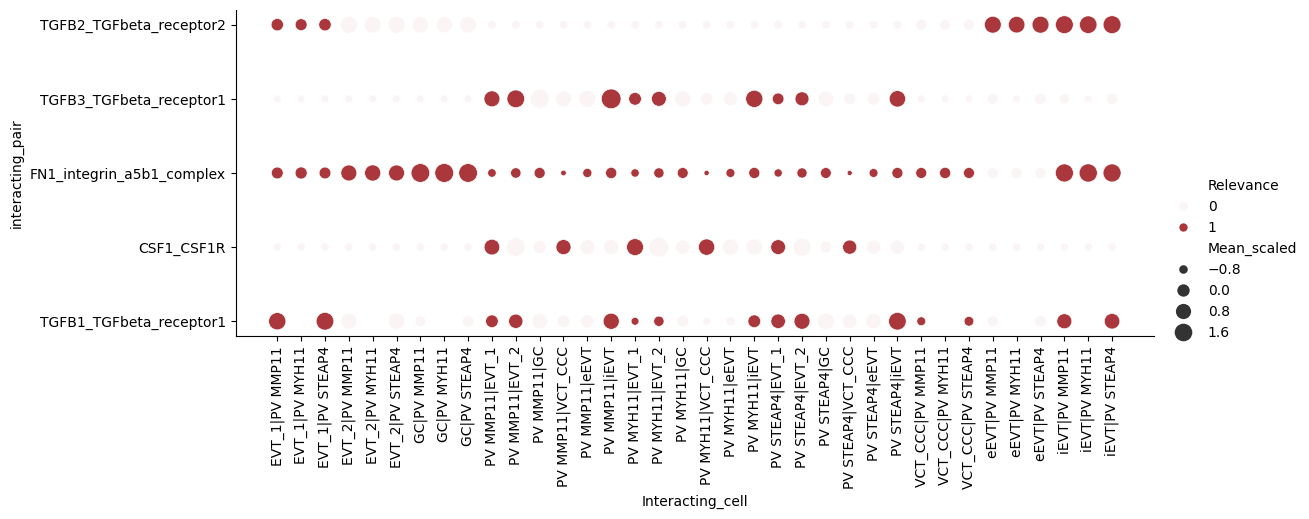

In [ ]:
import seaborn as sns
# 导入 Seaborn 库，用于绘制统计图形。

g = sns.relplot(
    data = relevant_interactions_plot,
    # 输入数据：经过处理和归一化的长格式 CellPhoneDB 结果 DataFrame
    x = "Interacting_cell",
    # X 轴变量：每个点表示的细胞对（如 'ClusterA|ClusterB'）
    y = "interacting_pair",
    # Y 轴变量：每个点代表的具体配体-受体对
    hue = "Relevance",
    # 颜色变量（Hue）：用于着色的变量，通常是相互作用的**统计显著性得分**（如 p 值或 Z-score）
    size = "Mean_scaled",
    # 大小变量（Size）：用于控制点的大小的变量，这里是**归一化后的平均表达强度**（Mean_scaled）
    # 目的：用点的大小表示 L-R 对的表达强度
    palette = "vlag",
    hue_norm=(-1, 1),
    # 颜色归一化范围：将颜色映射范围限制在 -1 到 1 之间
    height = 4,
    aspect = 3,
    # 图形纵横比：设置图形的宽度是其高度的 3 倍，以适应长 X 轴标签
    sizes = (0, 200)
    # 点的大小范围：设置点的最小和最大像素大小
)

g.set_xticklabels(rotation = 90)
# 旋转 X 轴标签：将 X 轴上的细胞对标签旋转 90 度
# 目的：防止标签重叠，提高大量细胞对时的可读性

或者，也可以用（[kt-plots 教程](https://ktplotspy.readthedocs.io/en/latest/index.html)）来显示 CellphoneDB 的输出。在这个例子中，我们将绘制由 TGFB2 和 CSF1R 介导的 PV 与滋养层细胞之间的相互作用。

In [ ]:
import os                      # 导入 os 模块，用于操作系统接口操作（如文件路径处理）。
import anndata as ad           # 导入 anndata，核心数据结构，用于存储和操作单细胞/空间数据。
import pandas as pd            # 导入 Pandas，用于数据结构（DataFrame, Series）操作和管理。
import ktplotspy as kpy        # 导入 ktplotspy，通常用于可视化分子网络或细胞通讯结果（如 CellPhoneDB 的结果）。
import matplotlib.pyplot as plt# 导入 Matplotlib 的绘图模块。

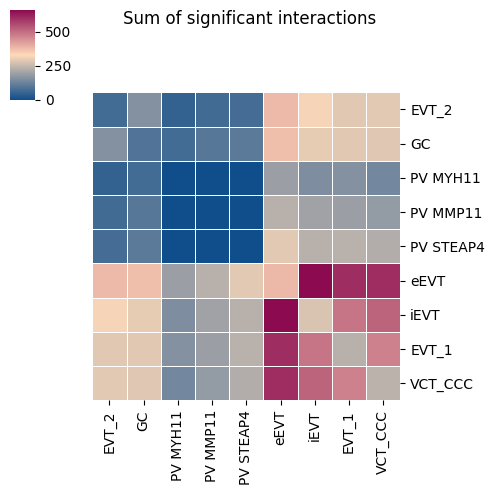

In [ ]:
kpy.plot_cpdb_heatmap(
    pvals = cpdb_results['relevant_interactions'],
    # P 值输入：使用 CellPhoneDB 结果中包含相互作用显著性信息（通常是 p 值或经过处理的相关性得分）的 DataFrame。
    # 目的：函数将基于这些值来计算显著相互作用的数量
    degs_analysis=True,
    # DEG 分析标志：设置为 True，指示热图应该显示**每个细胞簇对之间显著相互作用的总数量**。
    # 目的：这通常是 CellPhoneDB 结果的汇总视图，用于快速识别通讯最活跃的细胞对
    figsize=(5, 5),
    # 图形尺寸：设置输出热图的大小为 5x5 英寸
    title="Sum of significant interactions"
    # 图形标题：设置热图的标题为 "Sum of significant interactions"
)
# 作用：
# 1. 汇总计算：统计每对细胞簇（行和列）之间有多少个 L-R 对的相互作用被认为是显著的
# 2. 热图绘制：生成一个对称热图，其中颜色强度代表显著相互作用的总数量。颜色越深，表示该细胞簇对之间的潜在通讯通路越多
# 目的：快速识别组织微环境中通讯最活跃的“发送方”和“接收方”簇对

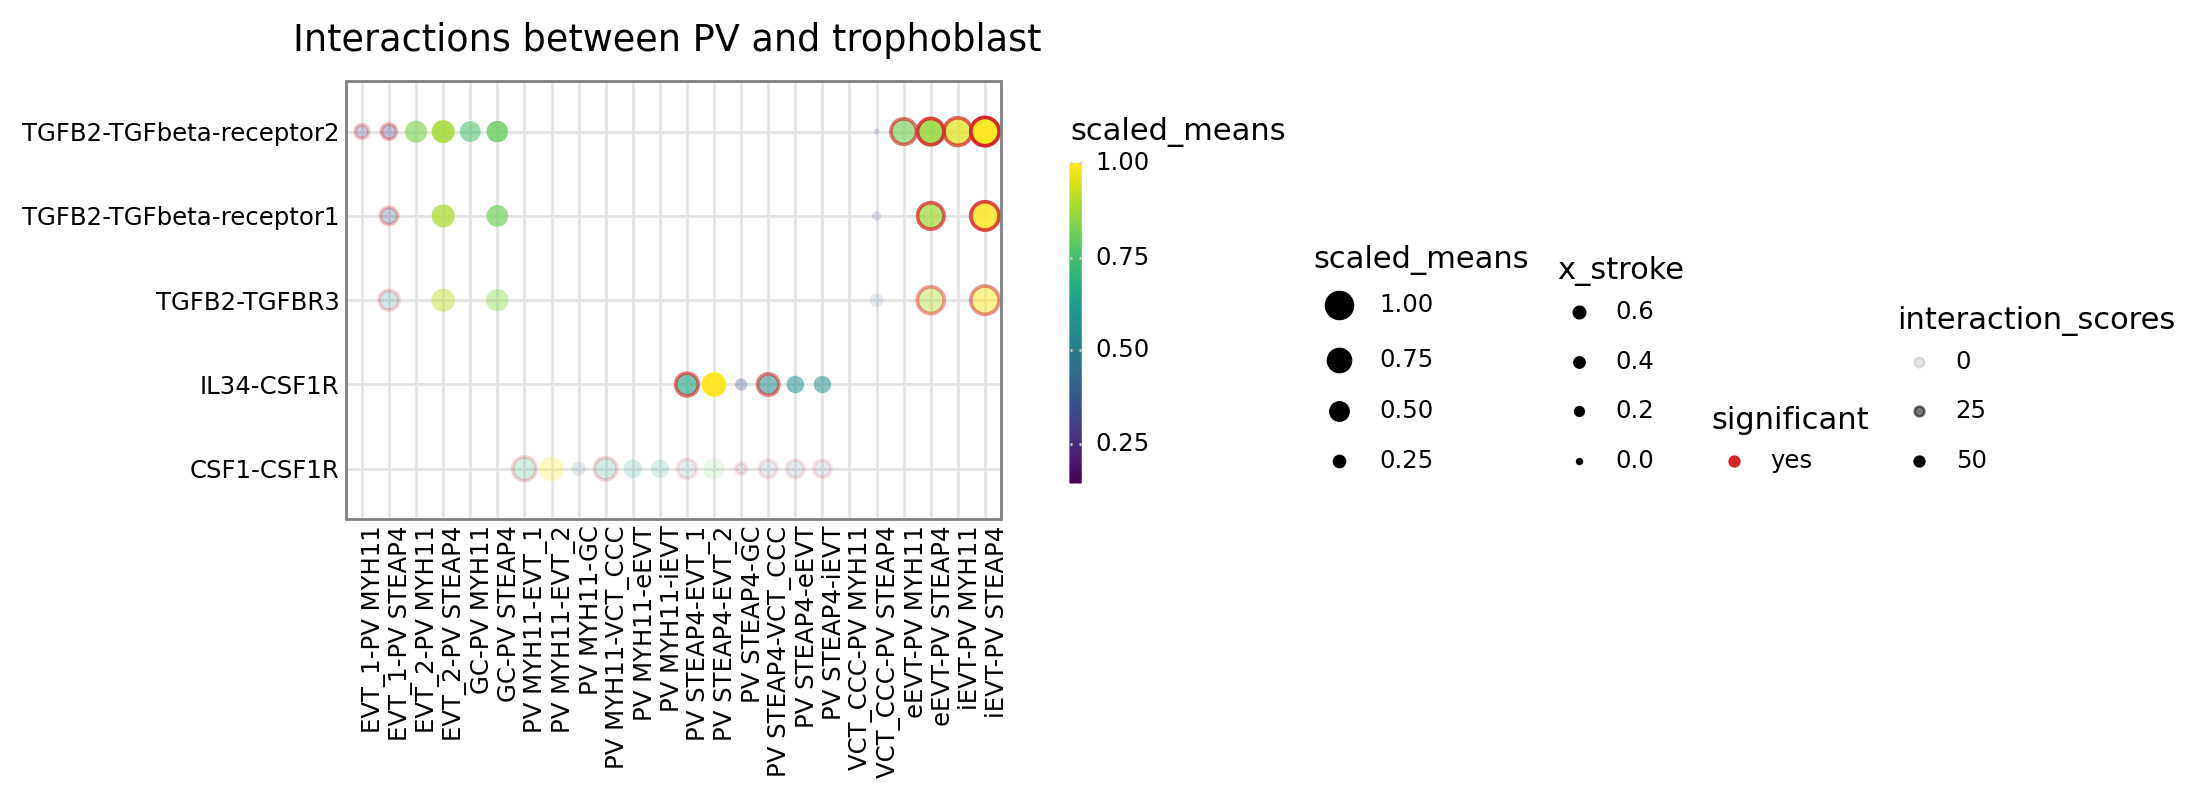

In [ ]:
kpy.plot_cpdb(
    adata = adata,
    cell_type1 = "PV MYH11|PV STEAP4|PV MMPP11",
    # 细胞群 1：定义第一组细胞类型（PV 细胞的子簇），这些细胞将作为图中的一侧（通常是发送方或接收方）。
    cell_type2 = "EVT_1|EVT_2|GC|iEVT|eEVT|VCT_CCC", 
    # 细胞群 2：定义第二组细胞类型（滋养层细胞的子簇），这些细胞将作为图中的另一侧
    means = cpdb_results['means'],
    # 平均表达值：CellPhoneDB 结果中的 L-R 对平均表达矩阵
    pvals = cpdb_results['relevant_interactions'],
    # 显著性值：CellPhoneDB 结果中的相互作用显著性矩阵
    celltype_key = "cell_labels",
    # 细胞类型键：指定 AnnData.obs 中用于定义细胞类型/簇的列名
    genes = ["TGFB2", "CSF1R"],
    # 关键基因：指定要在图中特别突出显示的 L-R 对中包含的特定基因
    figsize = (11,4),
    # 图形尺寸：设置图表大小
    title = "Interactions between PV and trophoblast ",
)

绘制相互作用 CellSign 结果（受体下游的活性转录因子）

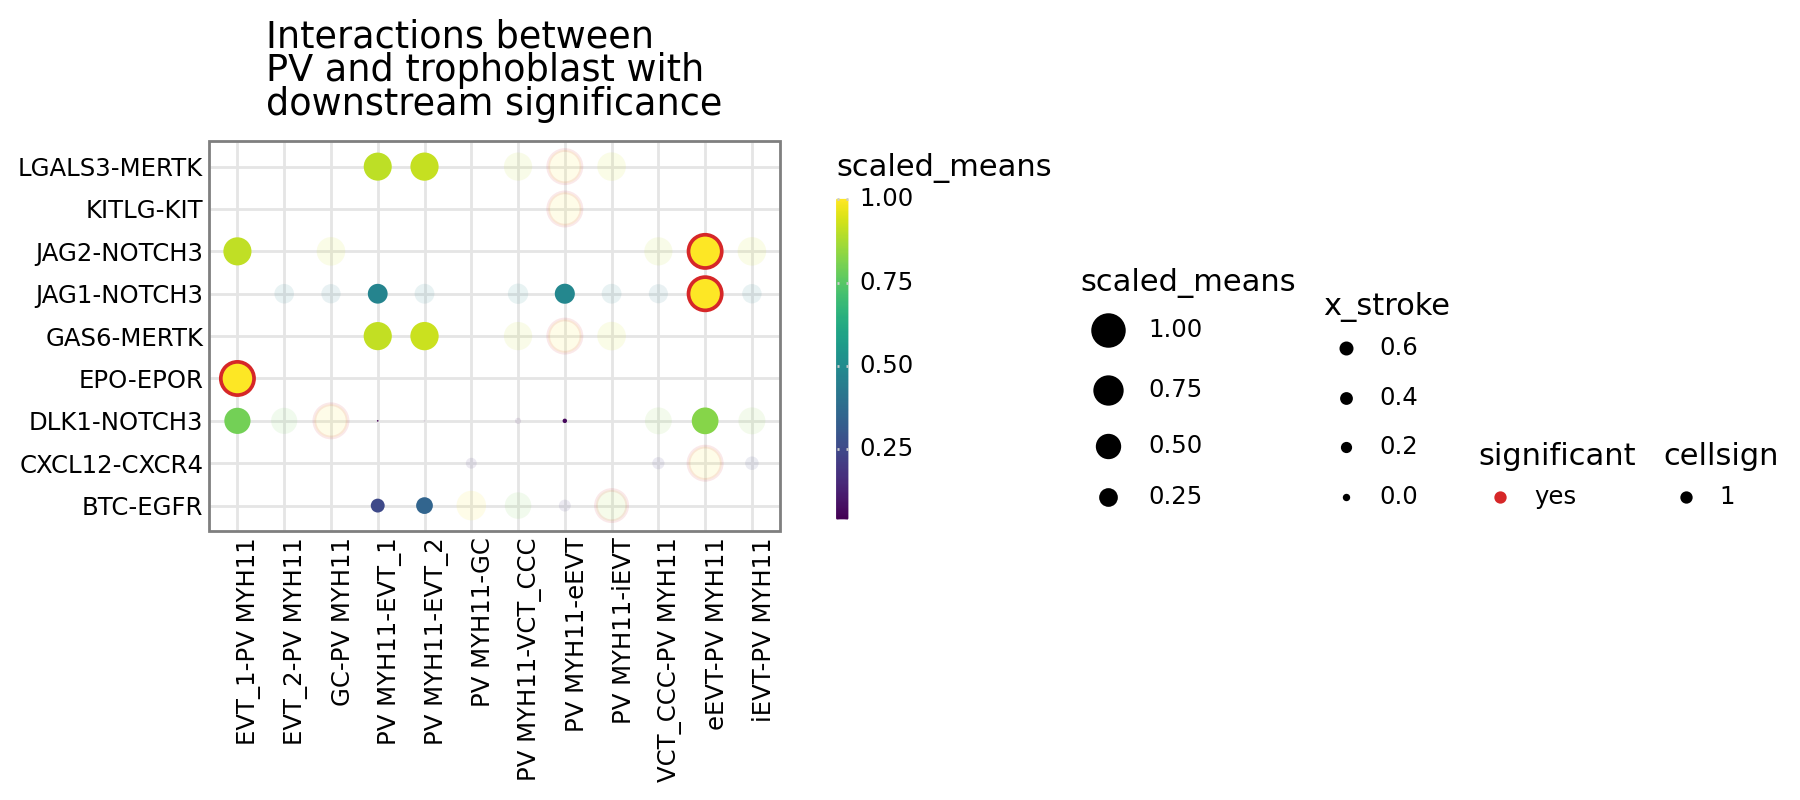

In [ ]:
kpy.plot_cpdb(
    adata = adata,
    cell_type1 = "PV MYH11",
    # [细胞群 1] 定义第一组细胞类型，这里是单个簇 "PV MYH11"
    cell_type2 = "EVT_1|EVT_2|GC|iEVT|eEVT|VCT_CCC",
    # [细胞群 2] 定义第二组细胞类型，即所有滋养层细胞亚型的组合
    means = cpdb_results['means'],
    # [平均表达值] CellPhoneDB 结果中的 L-R 对平均表达矩阵，用于设置点的大小
    pvals = cpdb_results['relevant_interactions'],
    # [显著性值] CellPhoneDB 结果中的相互作用显著性矩阵
    celltype_key = "cell_labels",
    # [细胞类型键] 指定 AnnData.obs 中用于定义细胞类型/簇的列名 
    figsize = (9, 4),
    # [图形尺寸] 设置图表的宽度和高度
    title = "Interactions between\nPV and trophoblast with\ndownstream significance",
    # [图形标题] 设置图表的标题，强调是具有下游显著性的相互作用
    max_size = 6,
    # [最大点大小] 设置图中点的最大尺寸，控制视觉动态范围
    highlight_size = 0.75,
    # [突出显示尺寸] 用于调节被选中的 L-R 对点的大小，使其更突出
    degs_analysis = True,
    # [DEG 分析标志] 指示绘图时考虑或突出显示涉及差异表达基因的相互作用
    standard_scale = True,
    # [标准化缩放] 对用于点大小或颜色的数值进行标准化处理（如 Z-score），使不同 L-R 对的比较公平
    cellsign = cpdb_results['CellSign_active_interactions'],
    # [CellSign 活性得分] 输入 CellSign 分析得到的活性相互作用得分矩阵  
    filter_by_cellsign = True,
    # [按 CellSign 过滤] 设置为 True，仅显示那些被 CellSign 鉴定为导致下游转录调控显著变化的 L-R 相互作用
    scale_alpha_by_cellsign = True
    # [按 CellSign 缩放透明度] 设置为 True，将点的透明度（alpha 值）与 CellSign 活性得分关联
    # 目的：用透明度表示下游信号转导的置信度，得分越高，点越不透明
)

也可以按性质分组不同的交互通路情况

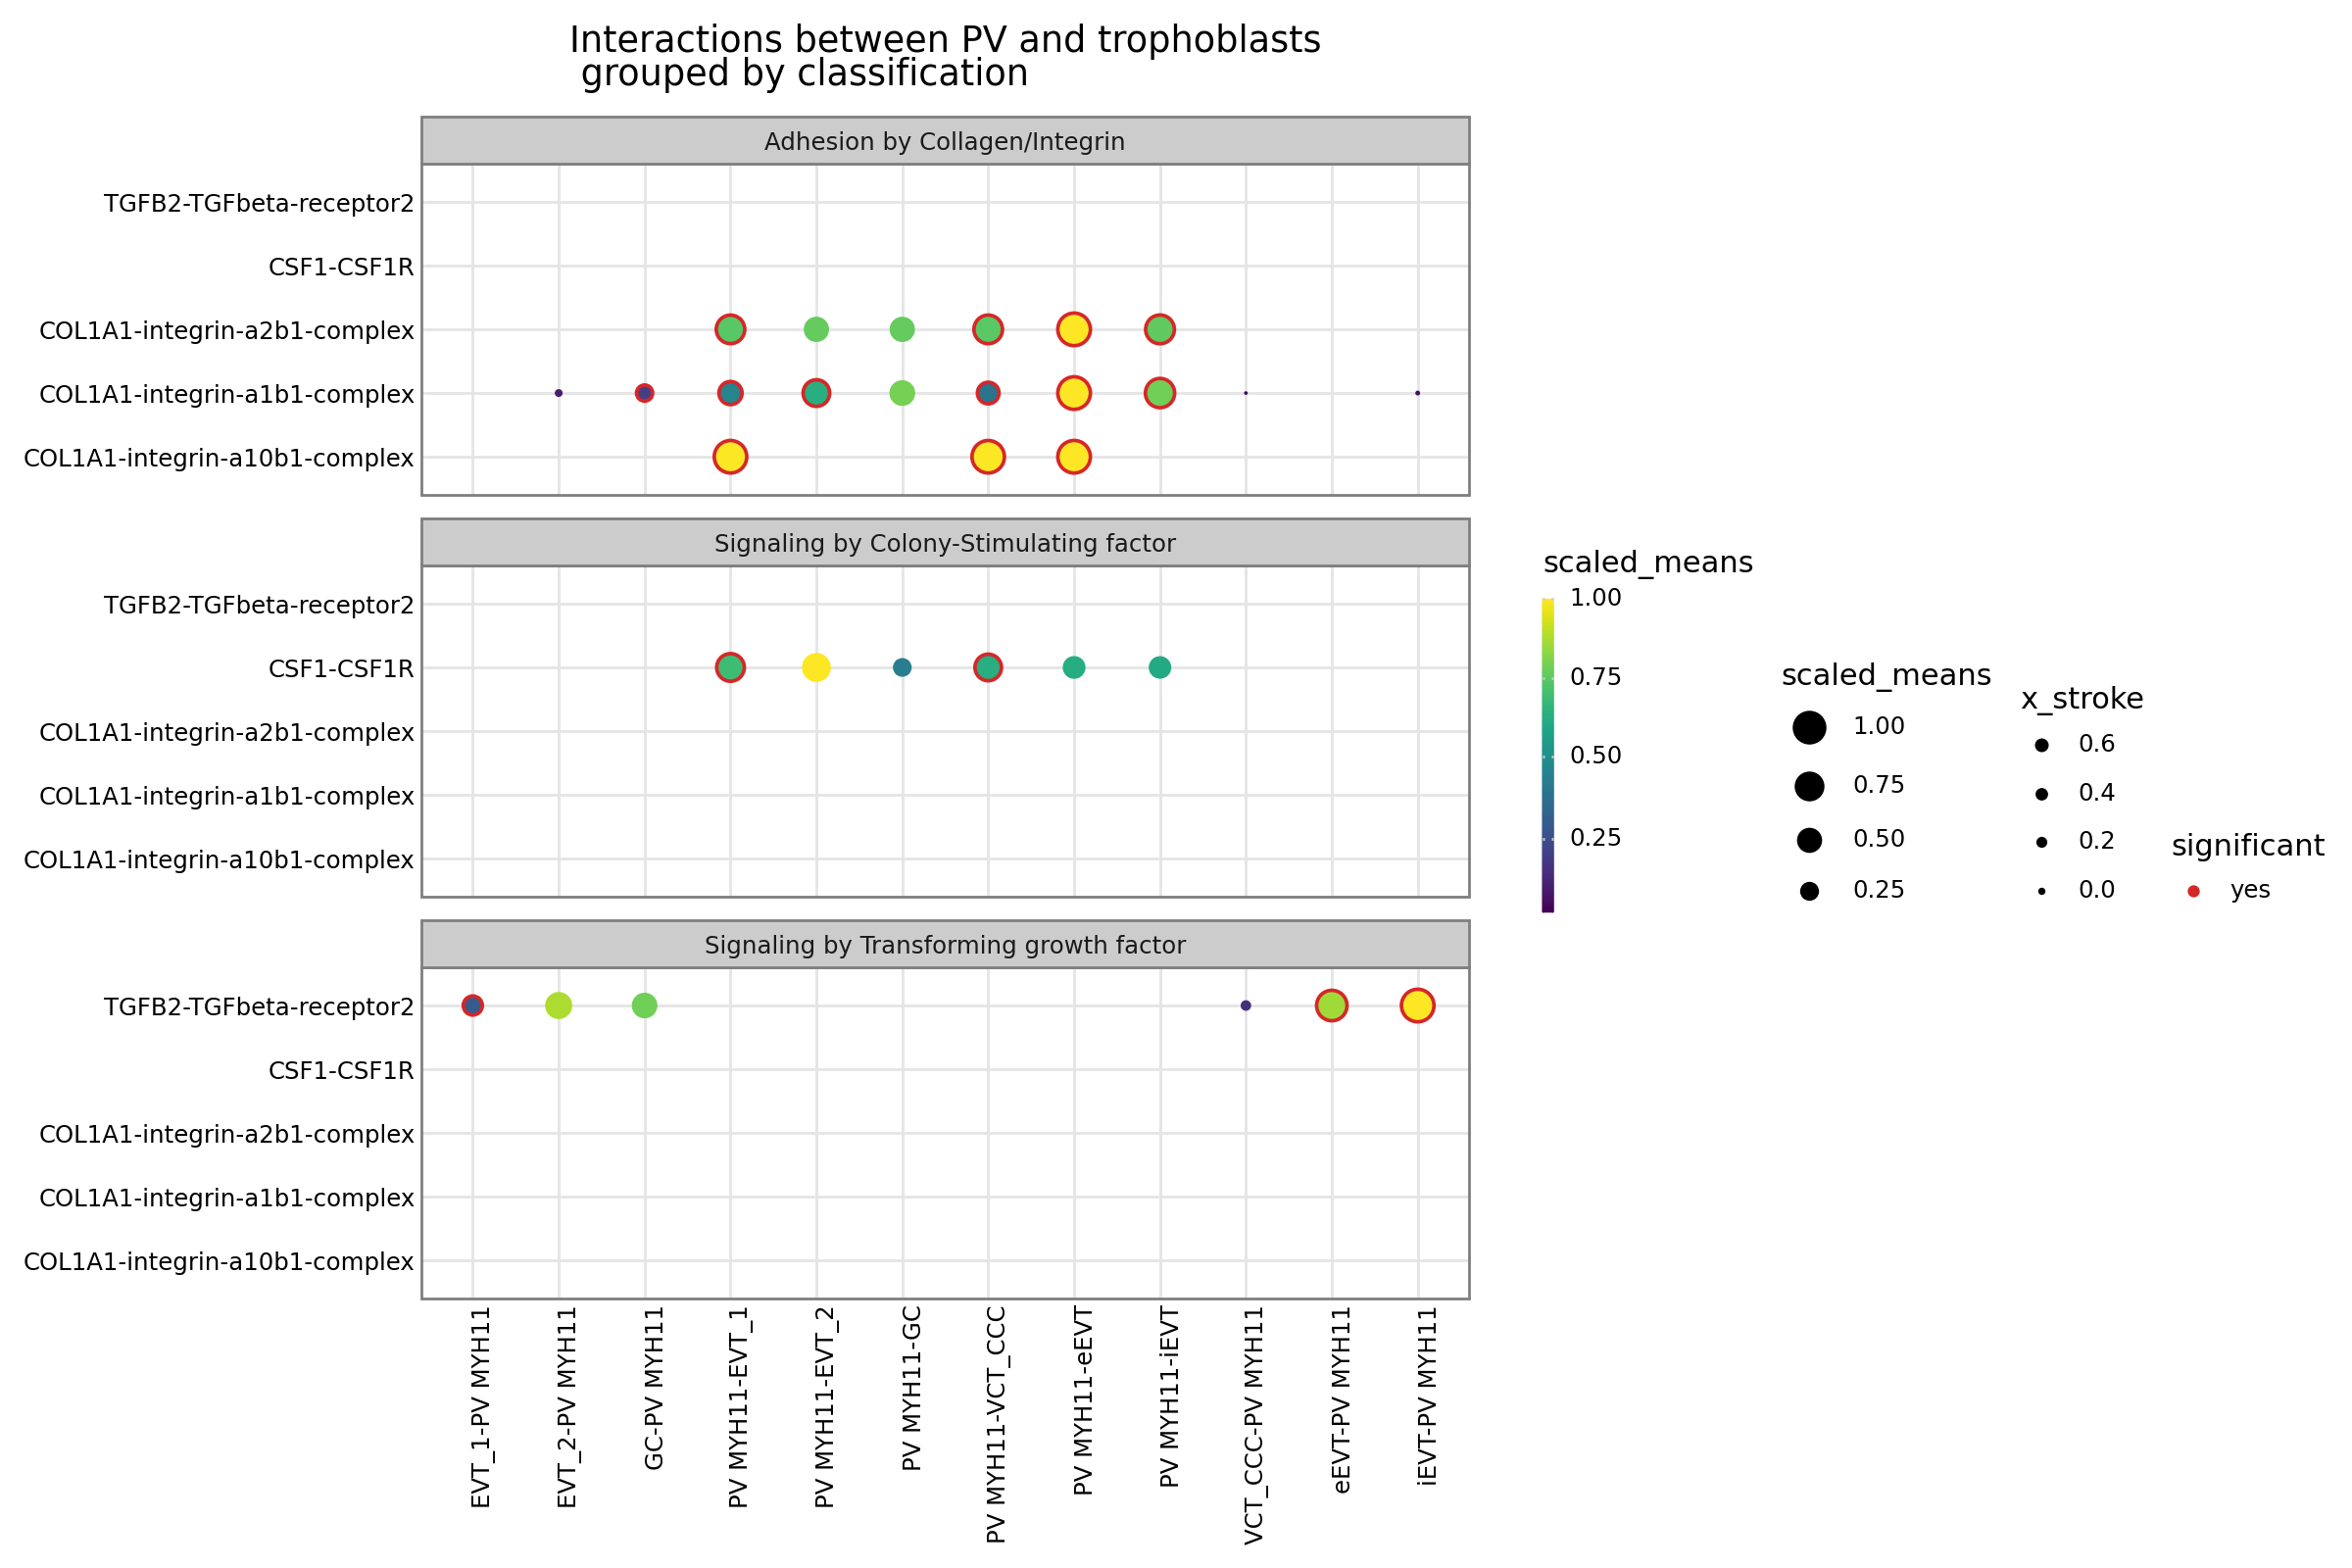

In [ ]:
from plotnine import facet_wrap 
# 导入 plotnine 库中的 facet_wrap 函数，用于分面绘图。

p = kpy.plot_cpdb(
    adata = adata,
    cell_type1 = "PV MYH11",
    # [细胞群 1] PV 细胞的一个子簇
    cell_type2 = "EVT_1|EVT_2|GC|iEVT|eEVT|VCT_CCC",
    # [细胞群 2] 所有滋养层细胞亚型
    means = cpdb_results['means'],
    pvals = cpdb_results['relevant_interactions'],
    celltype_key = "cell_labels",
    # [数据输入] L-R 强度、显著性数据和细胞类型标识符
    genes = ["TGFB2", "CSF1R", "COL1A1"],
    # [关键基因] 指定要在图中高亮显示的 L-R 对中包含的关键基因
    figsize = (12, 8),
    title = "Interactions between PV and trophoblasts\n grouped by classification",
    max_size = 6,
    highlight_size = 0.75,
    degs_analysis = True,
    standard_scale = True
)
p + facet_wrap("~ classification", ncol = 1)
# 核心操作：将上面创建的图表对象 p 与 facet_wrap() 函数相结合
# - "~ classification": 指定使用 L-R 对的 'classification'（分类，例如：趋化因子、细胞因子、粘附分子等）列作为分面的依据
# - ncol = 1: 指定将所有分面图垂直排列，每行只有一列
# 目的：将所有的 L-R 相互作用根据其生物学功能或类型进行分组，并在单独的小图表中展示。这使得用户可以专注于查看特定类别的 L-R 通路在 PV 细胞和滋养层细胞之间的活跃情况

# 环境信息

In [ ]:
import subprocess
subprocess.run(['conda', 'list'])

# packages in environment at /home/chenao/miniconda3/envs/cpdb:
#
# Name                     Version          Build               Channel
_libgcc_mutex              0.1              conda_forge         conda-forge
_openmp_mutex              4.5              2_gnu               conda-forge
anndata                    0.10.9           pypi_0              pypi
array-api-compat           1.11.2           pypi_0              pypi
asttokens                  3.0.0            pypi_0              pypi
biopython                  1.85             pypi_0              pypi
bzip2                      1.0.8            h4bc722e_7          conda-forge
ca-certificates            2025.7.14        hbd8a1cb_0          conda-forge
cellphonedb                5.0.1            pypi_0              pypi
certifi                    2025.7.14        pypi_0              pypi
charset-normalizer         3.4.2            pypi_0              pypi
comm                       0.2.3            pypi_0              pypi
contou

CompletedProcess(args=['conda', 'list'], returncode=0)

In [2]:
subprocess.run(['pip', 'list'])

Package             Version
------------------- -----------
anndata             0.10.9
array_api_compat    1.11.2
asttokens           3.0.0
biopython           1.85
cellphonedb         5.0.1
certifi             2025.7.14
charset-normalizer  3.4.2
comm                0.2.3
contourpy           1.3.0
cycler              0.12.1
debugpy             1.8.17
decorator           5.2.1
exceptiongroup      1.3.0
executing           2.2.1
fbpca               1.0
fonttools           4.59.0
geosketch           1.3
get-annotations     0.1.2
h5py                3.14.0
idna                3.10
importlib_metadata  8.7.0
importlib_resources 6.5.2
iniconfig           2.1.0
ipykernel           6.30.1
ipython             8.18.1
jedi                0.19.2
joblib              1.5.1
jupyter_client      8.6.3
jupyter_core        5.8.1
kiwisolver          1.4.7
ktplotspy           0.2.4
legacy-api-wrap     1.4.1
llvmlite            0.43.0
matplotlib          3.9.4
matplotlib-inline   0.1.7
mizani              0.

CompletedProcess(args=['pip', 'list'], returncode=0)

# 单细胞教程全收录
[B站视频](https://www.bilibili.com/video/BV1S44y1b76Z/):先看一遍视频再去看推送操作，建议至少**看三遍**  
以下的资料都可以在这里订阅：
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Seurat V5更新版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519711&idx=1&sn=d25d4f5daf609bda8367f16db676ecf3&chksm=9b3cf48fac4b7d99e65eba6d4c66c63e40b1d187fa1d9e6449d6cd07d5dec5127cff54886f93&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Python版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504877&idx=2&sn=2b56a9cfa19fcc918ee6c2ed88fed017&chksm=9b3caabdac4b23ab6e28425a4a5eb4d40ee3612e51f84f5d1e53ac91bef93f717e9e754398e3&scene=21#wechat_redirect)    
 
## 单细胞测序基础数据分析**保姆级教程**，代码部分整理在往期推送之中：
[手把手教你做单细胞测序数据分析（一）——绪论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499776&idx=2&sn=7fc250d94ed88cfd5e2224f071bb1742&chksm=9b3cb950ac4b30467a082527547b91aec15b7d1f40d44e362894aedeb6a99e014518fa5e4743&token=767842863&lang=zh_CN#rd)  
[手把手教你做单细胞测序数据分析（二）——各类数据结构与读取方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499795&idx=2&sn=68e6298eb43633c71939c146d90230ff&chksm=9b3cb943ac4b3055e09739d77e037d679f3d9ec68780d1aa8c592f806fcc8d2322eaee78752d&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（三）——单样本分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500010&idx=2&sn=2f9fd1b0101d579bcd250fdc24e98bfc&chksm=9b3cb9baac4b30ac6f0ce28a6dd10470e73d1e1d6defece5636939a32a6db9b2cce0ff8688eb&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（四）——多样本整合](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（五）——细胞类型注释](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（六）——组间差异分析及可视化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（七）——基因集富集分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500357&idx=2&sn=40034079b771c478b482e849ed4b216c&chksm=9b3cbb15ac4b3203d517ff71073ab0520fe144bc108b7a26f6b17e88fb63a78c5777946618e3&scene=178&cur_album_id=2923694853375688706#rd)  
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)    
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)
  
## 单细胞图片改造计划
[改造单细胞降维图| 1.DimPlot的探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496162&idx=1&sn=598c2920f7cc0697ee5a1fa6cadaee04&chksm=9b3c88b2ac4b01a415feeebbbec6c4891319439dc8dcdafd33cca7a1222e5adc723ae9d3a73d&scene=21#wechat_redirect)  
[改造单细胞降维图| 2.ggplot2中的DIY](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496239&idx=1&sn=1fe6fd4a7fb88ecc0456b4f5710cb5d6&chksm=9b3c8b7fac4b0269e0abeab951ad6ae0ddd1464dd9d1867280eeb9755fda5ba8f5237d88a7a6&scene=21#wechat_redirect)  
[改造单细胞降维图| 3.3D降维图与动图绘制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498080&idx=2&sn=a9bcf65e3ae34ba201e8d49ee33c0728&chksm=9b3c8030ac4b0926c3f059a9a5d23f1bcdbcaf8e5a562eba2b7e3bec3396c44573269bd08e7b&scene=21&cur_album_id=2707677276481814529#wechat_redirect)  
[改造单细胞降维图| 4.一些造好的轮子](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498191&idx=1&sn=952312a6b26232d460bf787cc276543f&chksm=9b3c809fac4b098972c8c1dd83b9f954a38fe5b5f6bc7e295f3f3a7ba6c4c3d32951679ac24d&scene=21#wechat_redirect)  
[沉浸式统计细胞比例](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503971&idx=2&sn=7dafb1e743ebbb95e488d8d1b7024448&chksm=9b3ca933ac4b2025f922a325ec6893e93613f130ff1d4fd609e2d7274f7f1fdb5134092e28ad&scene=21#wechat_redirect)  
[改造单细胞FeaturePlot](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504616&idx=1&sn=f7b4a0e6b25d224380cd803e3463a3e4&chksm=9b3cabb8ac4b22aeb65e0d6ec32a1f8674dcf907da078ccb3b61e06c4aa035864ebec092f571&scene=21#wechat_redirect)  
[VlnPlot用法及ggplot复现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504768&idx=1&sn=4fc5eb47037d3a80178e32975488d70b&chksm=9b3caad0ac4b23c61147cfb0f46ecd846568f37ce89c963eb5f069d3e89a8ba285897726bb3d&scene=21#wechat_redirect)  
[VlnPlot的ggplot改造](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504843&idx=1&sn=b795a3e36ae092d8f87abb5a87187828&chksm=9b3caa9bac4b238dd33e905c33924b58aa4ff14e83abbf08046fba7fe765ecb0204163cb6acf&scene=21#wechat_redirect)  
[改造单细胞DotPlot](https://mp.weixin.qq.com/s/GPp-QYwT6jOjFfeZjs9hZg)  
[改造单细胞DoHeatmap](https://mp.weixin.qq.com/s/V_JhpBOy1wG6U-uQsj8CPQ)   

## 3、SCENIC转录因子分析：
[1.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500098&idx=1&sn=8c31241bd259e303a6ac3c9740f298d9&chksm=9b3cb812ac4b31046fd298c8ee5f0bc0de445df62b234bd934c34ca655e61de3da54d81e2053&scene=21#wechat_redirect)  
[2.学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500439&idx=1&sn=d6b4874a8352f5b7a4165629c03058ce&chksm=9b3cbbc7ac4b32d158fd3c5c2f155c54c892d40eaae3718409936fc319f69705da32badf79d6&scene=21#wechat_redirect)  
[3.软件安装与数据准备](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500631&idx=1&sn=5d73db4dcc74b66de07dee9db910bb83&chksm=9b3cba07ac4b3311d1820bb305778aea707294f19fd6ff2631cd003da80bdcff8f8bc8ed34de&scene=21#wechat_redirect)  
[4.精简版流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501260&idx=1&sn=f1e2a165599e753e2959aad7c8a298cb&chksm=9b3cbc9cac4b358a9499654a2f95fa9010309ee4f408ef8b1f31ceb1a0f263ce22e8b511c430&scene=21#wechat_redirect)  
[5.step1+step2构建共表达网络与regulon](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501692&idx=1&sn=3f7e263a93942ad03faa1ba5f8694ec4&chksm=9b3cbe2cac4b373af9db74a50ffb08a9b8a3b958fc6385c937385f0f7323bc935cdb0fe5275c&scene=21#wechat_redirect)  
[6.Step3 利用AUCell对Regulon评分](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501989&idx=1&sn=2700bf779d7d261a4d751d1635fdce2c&chksm=9b3cb1f5ac4b38e3014476242fe956cf510cc45b9f4cef86070af8094fd5f884f9d5c3a3363f&scene=21#wechat_redirect)  
[7.Step4 二元矩阵的计算与可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503995&idx=1&sn=26c7e9ec56af434e62b02853cfe667d6&chksm=9b3ca92bac4b203d7986645ab5a3fb574f44185c7ced8bd47957fa237d436a95bfa2579d052a&scene=21#wechat_redirect)  
[8.Step5 regulon聚类、分群、降维](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504024&idx=1&sn=143c0ec4d94b8fca0a4a47d3dc24415b&chksm=9b3ca9c8ac4b20de70a87acb2d3f810b0e1497071b1c6f14f1882a6d844fff016e9ba5581eb3&scene=21#wechat_redirect)  
[9.下游探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505276&idx=1&sn=949c753feb85d5877121433caaa33013&chksm=9b3cac2cac4b253affb587a937d3f5e0576851a4f4e1570cb7510a594d155873961bbd91758d&scene=21#wechat_redirect)  
[SCENIC转录因子调控网络图](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520750&idx=1&sn=496bead1531a7eddd5c286030d350745&chksm=9b3ce8beac4b61a8589a1f8a66bd0571e09c0646655b6d805348bf6f4a0c7b52851615c22868&scene=21#wechat_redirect)  
  
## 上游**fastq**文件处理：
[单细胞分析的最上游——处理Fastq文件：cellranger](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484923&idx=1&sn=b5876af14fbee68d1e9db4b0f70cd1c8&chksm=9b3f7cabac48f5bdb3aac7d20201d89121a83720b41a10017564fedbb8c4a13df0da92daffd7&scene=21#wechat_redirect)  
[单细胞分析的最上游——处理Fastq文件：dropseqRunner](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484937&idx=1&sn=4fe1fa518202bdaf462bb93a2614ed32&chksm=9b3f7f59ac48f64fafaf34bac2c80f06d3a86b6a84ccf12566c7eac25bb71c7edd3d74004cf7&scene=21#wechat_redirect)    
[Cellranger报错：Unable to distinguish between](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504739&idx=2&sn=e4e6ad0559b9b6a703d6ab37c2a8fdb0&chksm=9b3caa33ac4b23257424184bda44dd600ad98bc0dfdfa90ab0e3ebaf208e598b0b710fbafa4b&scene=21#wechat_redirect)  
[BD Rhapsody平台单细胞转录组定量流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506542&idx=1&sn=99cf7af7fc0d56b0d6fe7ea3596df2b6&chksm=9b3ca33eac4b2a28e6682a7cf0b2091a387a06ecf89ee10737cf2194286ec0bba472ef1c2b90&scene=21#wechat_redirect)  
[BD Rhapsody定量输出文件读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519706&idx=1&sn=9d084bd8edf6ab4d9184672e5a4a2722&chksm=9b3cf48aac4b7d9c16ef85de7a5f33e65552bbba5d11d2170237063cf754fe9ff376647d3bd7&scene=21#wechat_redirect)  
  
## **细胞通讯**
[跳转B站，连播更方便](https://www.bilibili.com/video/BV1Ab4y1W7qx?p=1)  
**往期推送**  
[《细胞通讯》CellChat学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501735&idx=2&sn=35fc792961507f4ae1cbae3a2882fba6&chksm=9b3cbef7ac4b37e1417d4108c8bd378c68c3907431ddfc52ad37c916e85649bb450d761a8e19&scene=21#wechat_redirect)  
[《细胞通讯》1.概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501282&idx=2&sn=cd37ea80e0b92f5bfbc98ea286e363da&chksm=9b3cbcb2ac4b35a4258d21fe003374795619fc2356376ebbe4ff640233f4b4c6e3e3ead41370&scene=21#wechat_redirect)  
[《细胞通讯》2.1CellChat基础分析教程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501296&idx=2&sn=fb3e252d95ee8b50cd446e71335b1aa0&chksm=9b3cbca0ac4b35b621b4f51d2c3a130f00461faeeff067396222c2fc2eeb53f3544664d7d9bc&scene=21#wechat_redirect)  
[《细胞通讯》2.2CellChat多组别分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501523&idx=2&sn=6fa803f256c2e0b945f93ae7d8245f50&chksm=9b3cbf83ac4b3695b587e9817840f419104c8680f5ef08ee39aa149b79852f48b179f68e3397&scene=21#wechat_redirect)    
[CellChat空转细胞通讯合辑](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512011&idx=1&sn=fbd41832c5995d79fead016931d3bfbd&chksm=9b3cd69bac4b5f8d16e7d8b8eeb5490e4938daf68902b06a8d60e25f150ec4ec459796f3aaac&scene=21#wechat_redirect)  
[SeekSpace细胞通讯分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511890&idx=1&sn=3457b875cd00b4433f50a39a45e1cb8a&chksm=9b3cd602ac4b5f144ad982dfbdf583b56d1bfb768e4e5f2cc9e5424af6e014e752835fadc8a6&scene=21#wechat_redirect)  
                              
## **拟时序分析**
[B站连续播放起来比较方便](https://www.bilibili.com/video/BV1br4y1x7Hf?p=1)  
**往期推送**  
[1.概论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486553&idx=1&sn=b689ec962a17ca1a1ada29ae8ff8c019&chksm=9b3f7509ac48fc1f0f81e288de8f15c86548215a1cd9d5c740dc63f2421371d13890398ab1df&scene=21#wechat_redirect)  
[2.monocle概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487001&idx=1&sn=329129e75f703e3f332e76af9c66871e&chksm=9b3f7749ac48fe5f081248c2a48c56685e3915015036c73f8f67ec3e6acc246ddf815daedb22&scene=21#wechat_redirect)  
[3.monocle2实操：精简版](https://mp.weixin.qq.com/s/k-1Jdc0J9EXb2jfwo7935w)    
[4.monocle2实操：完整版](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497730&idx=2&sn=930dc0e276219d70c937e943119388ff&chksm=9b3c8152ac4b08446d457cef3ede4a4a17c0ebacaec0c36efe7d7c8706fb4a3d62222d702ee5&scene=178&cur_album_id=2820794880947159043#rd)  
[5.初识monocle3](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489044&idx=1&sn=061dbfc34d200b73a8227d0bb28a1d27&chksm=9b3f6f44ac48e65251f7e5ecce84637c05d50ecb92769e8386f221f8e7b9bfeb719232def863&scene=21#wechat_redirect)  
[6.monocle3的降维、分群、聚类](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489494&idx=1&sn=44f0a44857c12fcf9a1ab84e4f2cbebf&chksm=9b3f6e86ac48e79026321de2fdca81a139d104d655884ffe87a68e0a1551ddffa5af7919d19e&scene=21#wechat_redirect)  
[7.monocle3的拟时序分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490418&idx=1&sn=18ae0b6139fe1a2436dcf6cc47850297&chksm=9b3f6222ac48eb3450de0b02a34eb5fff2db89ab8f155460d554cbb23be0cd27fd349079e7b2&scene=21#wechat_redirect)  
[解决monocle2的orderCells报错的两种方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491083&idx=1&sn=c5697ab024193cb6595d27e4f4d3bfaf&chksm=9b3f675bac48ee4d7244d9819e14fe210f7e42e40fc7a6a8df7b95bfd92f06334d60d226cb93&token=333450324&lang=zh_CN#rd)  
[一文搞定拟时序分析的下游可视化探索](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497634&idx=1&sn=64872660e8ce80ff08c6c0745c2b241b&chksm=9b3c8ef2ac4b07e4a2ef03870c91fdc1c3ded245dcecd5a2049841cb7e9749bd1cd0852133f1&scene=178&cur_album_id=2820794880947159043#rd)  
  
## 单细胞拷贝数变异
[单细胞拷贝数变异学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522733&idx=1&sn=4e3a0707fd8f83b5ad9377bc91ee8e53&scene=21#wechat_redirect)

## scATAC
[scATAC分析学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521636&idx=1&sn=208907010f3f7412c1c91343d7dfb0d3&scene=21#wechat_redirect)  
[一文了解单细胞染色质及常见分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522998&idx=1&sn=843d378d3b679951ad3c8e5da7c32d87&scene=21#wechat_redirect)  
[一文了解染色质可及性和表观基因组调控](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510114&idx=1&sn=f7e8b1df1804a6bba0d79b1ffec2467c&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&scene=21#wechat_redirect)  

## **scFAST系列**
[01.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503875&idx=1&sn=2b5ca0c57e17e51abb52adfe199c5736&chksm=9b3ca953ac4b20450f643b94bcfc95aa2b04ded197ce93e455a281901d7ccba099b48cfd03d9&scene=21#wechat_redirect)  
[02.单细胞分析准备工作](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504023&idx=1&sn=4091a22e853242b4aae7a7d3b4008f5c&chksm=9b3ca9c7ac4b20d1bb0389fad5fe85a3c4cf49179747fe97dffaab1087b7d2793668d9f63aa4&scene=21#wechat_redirect)  
[03.fast模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504044&idx=1&sn=d37991280217dcc29280efa344f856bb&chksm=9b3ca9fcac4b20eab124ccd4ba6ad3f5eee640df314e7d8fec0225035f06178e3a51dbe2033f&scene=21#wechat_redirect)  
[04.Seurat分析及可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504435&idx=1&sn=c6a6f7ca00684601f3cda49e53be5339&chksm=9b3cab63ac4b2275d993bbaa64c71652685065fa377be57319fc6a5c47eb958b3644c7459cd5&scene=21#wechat_redirect)  
[05.mut模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504878&idx=1&sn=2c5d9fc694eaf3e264c38b0691cd3a43&chksm=9b3caabeac4b23a87d201009137572c02ba1ea0dd747bcd8b8c02878b45917b6e235551c41cb&scene=21#wechat_redirect)  
[一文学会scFAST-seq数据分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505213&idx=1&sn=5f4ed0587dd96149d127a98d36f721f0&chksm=9b3cac6dac4b257bbc00c4647382d27883139bf06ab3071947bf1cccde8d1d501006dabab5f1&scene=21#wechat_redirect)  
  
## 其他单细胞相关**技术贴**:
[应审稿人要求| pseudo bulk差异分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521437&idx=1&sn=d47b48170f7189b8fb74b2316d0c4898&chksm=9b3cedcdac4b64db43487176203e52e53fe08e01ce819a1615fa1e2f9f8d513bbd4efdee5558&scene=21#wechat_redirect)  
[genesorteR——比FindAllMarkers快一百倍！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521266&idx=1&sn=2a74f282222b694f51362445e65c85a6&chksm=9b3ceaa2ac4b63b4a721d1134317af5ee1c9fbe844383a1f404249748e506b674ea26e66d0d2&scene=21#wechat_redirect)  
[单细胞必修课——Seurat流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512220&idx=1&sn=c71bc3f1ef007eb29be8b3b4ec10f0af&chksm=9b3cc9ccac4b40da749d2388dc2d885239a1e4f6ea0989f36b031c7253ce103b061e2605ad8c&scene=21#wechat_redirect)  
[scRNA-Seq双细胞过滤手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511622&idx=1&sn=60b35668e569267bab14ec8fbba8bd74&chksm=9b3cd716ac4b5e00122eac47f55085198040a4a0e97c56895bbc39f3a9f1a1eb4eba27048a8f&scene=21#wechat_redirect)   
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)  
[快速上手Seurat V5](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509880&idx=1&sn=3b7cd169ccfe688d10cb1ca70dc91e91&chksm=9b3cde28ac4b573ec6d5f4bceafa4294c0e9a001b7d0c0b64f274a9978b1438eeccc747ca0c0&scene=21#wechat_redirect)  
[单细胞Figure 1常见图表(视频教程)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509260&idx=1&sn=9ff90a428c3f22d43a31ec864e2d8a94&chksm=9b3cdc5cac4b554a2f7cb2a6368f7df9a9a3f6e406eb070663f53d81841a76e188c0b50727de&scene=21#wechat_redirect)  
[SCTransform与ScaleData](https://mp.weixin.qq.com/s/6jwfDa22EUgo2wYpmxCCFg)  
[细胞的数量由誰决定？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484056&idx=1&sn=4967a054f5241ff3a1bd4a6fe9a502b1&chksm=9b3f7bc8ac48f2deca3141461be035deb8658be184d78597af28f8ba2092d12f020768275248&scene=21#wechat_redirect)  
[单细胞中应该如何做GSVA？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484701&idx=1&sn=ad90680f252d092a2e21f349c8f32cab&chksm=9b3f7c4dac48f55bf1d11337406ab0e1295e8e1731dbac0715eedc99d11beff7f380e42dd49b&scene=21#wechat_redirect)  
[答读者问（三）：单细胞测序前景](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484280&idx=2&sn=844af02070012a1c2681880596ba51a2&chksm=9b3f7a28ac48f33e95eb906121be8953410ca4c572c8035cb801609a56caf9dcff57fa989602&scene=21#wechat_redirect)  
[答读者问（四）：如何分析细胞亚群](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484316&idx=2&sn=e8d02fddc80d1137bb64c55541f1651d&chksm=9b3f7accac48f3da7df7fcad9c996291bc66967c04d16dde92ed391c56e610a7298ac8fb7dbb&scene=21#wechat_redirect)  
[答读者问（八）：为什么Read10X也会报错?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485012&idx=1&sn=6007c8d7cb2a236dd7240a678dac0391&chksm=9b3f7f04ac48f612f811c1df9e9450dc8112d343e4bf245be5149c2e2a073d3e339cd0e3ff61&scene=21#wechat_redirect)  
[答读者问（十）整合后的表达矩阵，如何拆分出分组信息？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485134&idx=1&sn=13f5f8c47d8af2beeca4e103a5f5e26d&chksm=9b3f7f9eac48f688b454a1062ee4e41f7072ac9d58e5466fa7ed4bb05018adbfe167bb3a445a&scene=21#wechat_redirect)  
[答读者问（十一）如何一次性读取一个目录下的cellranger输出文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485145&idx=1&sn=402cb28c16aba0dc647037c9b7aba8f7&chksm=9b3f7f89ac48f69fe27cd427df3eff2e88c240bf20dfe92d8b522eecd7302d132d880bf29047&scene=21#wechat_redirect)  
[给你安排一个懂生信的工具人（十）：不学编程 零代码完成单细胞测序数据分析：Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485730&idx=1&sn=42b9b35026bec5359ac34750dea3bf44&chksm=9b3f7072ac48f964970f673a86e27ecd453a80b953168dc110e0ea6bfa4110eeed3350c9601a&scene=21#wechat_redirect)  
[什么？不做单细胞也能分析细胞类群和免疫浸润？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485798&idx=1&sn=c849bc7a0093af92fc99e13b55842bb2&chksm=9b3f7036ac48f92048d726b38f2dd978d0b0cce779c1a4090aa4da5cb2df3ad30a5c5dbed27e&scene=21#wechat_redirect)  
[答读者问 （十三）查看Seurat对象时的ERROR：type='text'](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485859&idx=1&sn=a014c4cb6034551e57c70820c7781e49&chksm=9b3f70f3ac48f9e52620e3ff197eb98e58836e8bb6baad634387a521fdda1e4a194356517c73&scene=21#wechat_redirect)  
[各类单细胞对象（数据格式）转换大全（一）](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485925&idx=1&sn=14e08440200f0f5cb4dcc2dc615efeb8&chksm=9b3f70b5ac48f9a37a43cc2a8b2a5e485a3f84b4ef87949dfe99056bc6301b110e80800f6bb1&scene=21#wechat_redirect)    
[单细胞对象(数据格式)转换大全|2. h5ad转Seuratobj](https://mp.weixin.qq.com/s/iYz4ZsD-oJ2ZJsZpbGKRsg)   
[批量整理好GEO中下载的单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486045&idx=1&sn=0b6874bcffc8abafb505cabce4c4fc0e&chksm=9b3f730dac48fa1b140ef01c07a7749e69df4fa7d2056deeed0673c668b6246724cd85741125&scene=21#wechat_redirect)  
[答读者问 （十四）Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)  
[答读者问 （十五）稀疏矩阵转matrix, as.matrix函数是下下策](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486259&idx=1&sn=97de5c9e15e48cb62c8a680376a4ee0d&chksm=9b3f7263ac48fb75a91b40416826fe35b340284cf38255925ac447443a62cdc1df082d20fb61&scene=21#wechat_redirect)  
[答读者问 （十六）做单细胞测序到底需要多少内存](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487923&idx=1&sn=15043c6d729b0d5493ab875b0e54a259&chksm=9b3f68e3ac48e1f5dae514a01c857f9a56a90e2977dd7862db28d06fe55888cd9bb4afbb14e0&scene=21#wechat_redirect)  
[答读者问 （十七）调用的线程越多就算的越快嘛?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488995&idx=1&sn=7140e0d037671542fb37dff3a3c94b28&chksm=9b3f6cb3ac48e5a5f54a02be9e6af9f5a4cf8da1de1770f9035130c84dedf059a024964fc15a&scene=21#wechat_redirect)  
[答读者问（十八）、一个我至少被问过30遍的monocle报错](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490010&idx=1&sn=24c55fa4bd5d7d829625cb67dbaf321a&chksm=9b3f608aac48e99c9f27e3423c8398034a1819d0ccebbf21170b955461d2c335132d6f3cce25&scene=21#wechat_redirect)  
[一文搞定单细胞基因集评分](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497831&idx=2&sn=82fa51c76a381fba0b444e9b6b23eb5f&chksm=9b3c8137ac4b0821dfb62e9b365ea3c32abbbd80df42df63181c37ad9ed991c0183c2c7981d8&payreadticket=HCkRKr7R3-O3p5-0VkAwOOfgIXR8STjX9HoZYYWKS3jgJtptsG2Mu4KWI6Pz6cAuCOxiFPM#rd)  
[没有barcode文件的单细胞数据要怎么读取](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490952&idx=1&sn=364a3941e59e45234795c906a42fc9ab&chksm=9b3f64d8ac48edcec70384cf5c6a91224d0f7841ce3a7cfcade6513500c13673a6695d6f0299&token=1760636281&lang=zh_CN#rd)  
[单细胞基因集评分之AUCell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491761&idx=1&sn=41f5c1ceaacf6a1c4840567f8a349e06&chksm=9b3c99e1ac4b10f7ca158561e96fec76a49ff32b8412cb146ed3fb7aa9260c75172b4eb16f9a&scene=21&token=7173752&lang=zh_CN#wechat_redirect)    
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=416896563&lang=zh_CN#rd)  
[粉丝来稿|1. Seurat4相较于Seurat3的几点改动](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494516&idx=1&sn=cb2d4e6b182428ce7b98e7fff2e8729a&chksm=9b3c9224ac4b1b32c4fe99758960305c4845395cfe03851d70a0407043ee36250e55d20106fc&scene=21&token=1634975705&lang=zh_CN#wechat_redirect)  
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=468535359&lang=zh_CN#rd)      
[答读者问（二十）四个单细胞样本只给了一套文件怎么读](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494879&idx=1&sn=c2287ab3684792747dfac53d6704462b&chksm=9b3c958fac4b1c994a4b075c4f8475816e121966fa8c52cb0a2ce8c14987988ab9bdb49bdf69&token=468535359&lang=zh_CN#rd)
[人类单细胞测序数据中有哪些以"**-"开头的基因](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495019&idx=1&sn=f52ac22ca1ea47ecddaa3503bdc2c0b6&chksm=9b3c943bac4b1d2d521f7155ce8f499389dade23828017572a84cdce71e5d08d37d74e08512b&scene=21&token=1624480671&lang=zh_CN#wechat_redirect)  
[为什么总把分辨率调的很高](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495765&idx=1&sn=2ec5e3e26491e28c92e25c40630bffae&chksm=9b3c8905ac4b0013a23f9cda2cccd67cdf3c4a941bac161e3a15a12ab98cd4e5eca8aeedbe96&token=133749967&lang=zh_CN#rd)            
[答读者问（六）：Seurat中如何让细胞听你指挥](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497669&idx=3&sn=ac3408c7dd28425426d954f81d283252&chksm=9b3c8e95ac4b0783c12182a960e8158c8a0992a20335f8c70f1dc63855c5984dd22e4dee706d&scene=178&cur_album_id=2820794880947159043#rd)  
[答读者问| 22.object 'CsparseMatrix_validate' not found](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496273&idx=1&sn=fd5a92dd7fdc349b1624784ca74b1220&chksm=9b3c8b01ac4b0217cf06d89bfea49c3fa0c9b580957338c0cc8f55ede3e8f65d6d7162ae27e3&scene=21#wechat_redirect)  
[单细胞数据在R中的读取及存储速度太慢怎么办？这个神包来帮你！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500270&idx=1&sn=11bdf3c7f9042fc03f9ed237a9b9677b&chksm=9b3cb8beac4b31a8bf1d9fb862553ed32ac9a56f4a6e0f2d38c9478132f87327d8c6b6940573&scene=21#wechat_redirect)  
[单细胞分群分辨率选择困难症](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501241&idx=1&sn=9e15d23f721ad7f4ae1335ce5362031b&chksm=9b3cbce9ac4b35ff43434c0384afbbf5689f5b62a677e55e8a635d4812da57593d85a73cf48b&scene=21#wechat_redirect)  
[一文搞定空间转录组与单细胞测序的整合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507210&idx=1&sn=f32037ffefd60b0d1bcca7bf9c3e0823&chksm=9b3ca45aac4b2d4cf0c68299db3a2891130d89d9e0fe2a9ecb34b394736550bcf7d7c51090cc&scene=21#wechat_redirect)  
[一文掌握十个单细胞数据库](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507979&idx=1&sn=e94225b592733f2e22b4b09245027365&chksm=9b3cd95bac4b504df8dc25d9c5cfddf56d3b47e7cc6f33a7ef369bc916c60abb6b49277b79f7&scene=21#wechat_redirect)  
[如何将已经构建好的Seurat空转对象转存为原始文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508133&idx=1&sn=297b8fb9cc8f33a1d19167dba1104e97&chksm=9b3cd9f5ac4b50e36df53e3e18bb2990d9635d88a725f1e54fc5eb5967ac9f0934b79cbb8b34&scene=21#wechat_redirect)  
[一文学会零代码单细胞分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511007&idx=1&sn=e7be3d9775890e5717889714629cfaf5&chksm=9b3cd28fac4b5b9936428d5f74d8b581b5cddc18d0fc42e2a5d75604cce080588d50f1304a17&scene=21#wechat_redirect)  
[SeekSpace| 会单细胞就会空间转录组](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511779&idx=1&sn=23868525d86a9ed7867a3837ed18612c&chksm=9b3cd7b3ac4b5ea502950d0278d68da978f6011b2597c3ec90fb77e79320883fb4a5be2d5399&scene=21#wechat_redirect)  
[10xGenomics官方可视化工具——Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519698&idx=1&sn=0135ef1763fc146252835f2bd7f728ec&chksm=9b3cf482ac4b7d949d0936f11b487d5da4fd8f235bb86f63e960e23785885b9db0d14897b63d&scene=21#wechat_redirect)  
[快速上手Cellranger](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521051&idx=1&sn=e2ab820001013bae6e35310e27897086&chksm=9b3cea4bac4b635ddbb74c29240896902b497cdc47f1f37d99fa0fb8a402375e513690f24e3f&scene=21#wechat_redirect)    
[单细胞/空转生信工程师自测卷(入门级)](https://mp.weixin.qq.com/s/2RvmlET91UkS-13pu3ZrVw)
[30w单细胞数据会吃掉多少内存？](https://mp.weixin.qq.com/s/0WoO08Yb80g7sa_R8s1ZwQ)

              
## 单细胞文献阅读
 [《Advanced Science》新型Arf1抑制剂促进癌症干细胞衰老并增强抗肿瘤免疫](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522233&idx=1&sn=287a380de741ff55f0ce78dc9c727985&chksm=9b3ceee9ac4b67ffd925abafeba2cb215a5984e6dc85f0d8607340a07ec9208f1d19eae0e04b&scene=21#wechat_redirect)  
[IF14.3| scRNA-seq+脂质组多组学分析揭示宫内生长受限导致肝损伤的性别差异](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520900&idx=1&sn=157134292ffc2e5df730c5ba8a357b61&chksm=9b3cebd4ac4b62c286543c30381e9b4fdb8b44b28d4fa902fb963bbd45b28e1d3f1bc98eb148&scene=21#wechat_redirect)  
[Q1临床设计+生信分析，单细胞揭示骨髓增生异常综合征中的造血功能异常&微环境中的细胞状态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520295&idx=1&sn=8f98781c4ecc8205bcfd2cfa86caed9c&chksm=9b3ce977ac4b60617583775dcd4f0b2e3133a4fec23f7c9b95ae42b26bae9b8f6ddcd1f5ccb0&scene=21#wechat_redirect)  
[13分+文章利用scRNA-Seq揭示地铁细颗粒物引起肺部炎症的分子机制](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511886&idx=1&sn=31c712d00377b0f0ed33703b5b4fbfd8&chksm=9b3cd61eac4b5f084fde14a2eb50356f2f40a66c608d38909f12a3d81f48cff029a09ce2ee8c&scene=21#wechat_redirect)    
[除了铁死亡，还有铜死亡？！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247518144&idx=1&sn=d036f1bb04b09eb73f53e2104d69404c&chksm=9b3cfe90ac4b77862f2f463b42132c7bfdb687a1b61d350dcf656117b1331271e179710fd4fa&scene=21#wechat_redirect)  
[scRNA-seq揭示脓毒症预后水平预测的关键靶点！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522281&idx=1&sn=f95eb12fdc340b8da1123ec6253e6fac&chksm=9b3ceeb9ac4b67afa587e5fa3a2a8960e9bb28a1ad6dc48e49120a76154417a4c8be95af90b0&scene=21#wechat_redirect)  
[《Narure Biotechnology》教你怎么"捏造"单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521498&idx=1&sn=925561221f12e2ef2846b897914cc692&chksm=9b3ced8aac4b649c9073ec8dcaae49d689acfaf3d2d8b0012b727ef75b8231088b4e176fa9ca&scene=21#wechat_redirect)    
[拟时序分析神包—monocle的三篇《Nature》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519064&idx=1&sn=173948cb696c7d33b90cd21b28986777&chksm=9b3cf208ac4b7b1e328fdc445f9aecd6cfb836fdb33767876ba1aa35c55098a2a071dbe8e2f0&scene=21#wechat_redirect)  
[测序技术的发展与应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495792&idx=2&sn=1aecc80b68f65f8a44a899df524038c0&chksm=9b3c8920ac4b0036b23268331b457a335b22b4fa3aed1db287ab79e7a4613df8d195bd11421a&scene=21#wechat_redirect)  
[单细胞测序解析糖尿病肾病中肾小球的动态变化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497682&idx=2&sn=7ef49191c5e334bb291ccdaa8ea444ae&chksm=9b3c8e82ac4b079425433938c831d528eddb9237efaca49acbc210e9cd715d057541589dc290&scene=178&cur_album_id=2802463431357661184#rd)  
[单细胞测序技术解析健康人与T2D患者的胰岛差异](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=1&sn=b7f8df758bc4d95b88969378c6dfbeee&chksm=9b3c8ea1ac4b07b7c6a0b5023ebf6c8ecd7d34741ab076baa0b564535d1d753bbf9dc5be5290&scene=178&cur_album_id=2802463431357661184#rd)  
[小鼠全肾单细胞测序开篇之作](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=2&sn=554d6a4e1b28b2e5303695fae5942a34&chksm=9b3c8ea1ac4b07b72323ce25cd49474a9228ec1aaa56243f57dca3f2f668dc42ab9cd58dca21&scene=178&cur_album_id=2802463431357661184#rd)  
[Nature也能白嫖？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497867&idx=2&sn=caeb8ed06ffd5239b58cebcd90843cf8&chksm=9b3c81dbac4b08cd9eec50978951a1b890ca08edec644ff75205a09ad1f067dff25d6ecb938e&scene=178&cur_album_id=2802463431357661184#rd)  
[一篇不花钱就能白嫖的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497840&idx=2&sn=1dacbfb190e11d2ff104e32f238cf8c4&chksm=9b3c8120ac4b08367bfe3a0dd8d55f21f5d13528826de3144a9a85ce9b1c9f4c710de703edae&scene=178&cur_album_id=2802463431357661184#rd)  
[高氧下小鼠肺发育损伤的ScRNA图谱](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498513&idx=2&sn=79845edf56a3023c59c73403d7b6494b&chksm=9b3c8241ac4b0b57793402686edc8c35aaa3b0959d3096b5122207fbb70ab809d1df5faee0d7&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十二）、IgAN & STRT-Seq](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485376&idx=1&sn=02e228d0993d8a653c8bb1d531021cdb&chksm=9b3f7e90ac48f78686d6d5953aeb192db4f28bf577dbebd76d9fabbe797f135b7fb08fb42867&scene=21#wechat_redirect)  
[老树开新花——EGFR、肿瘤、免疫+scRNA-Seq](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498596&idx=2&sn=8f63f5856cdf90e15f1d19b4cfe6a39e&chksm=9b3c8234ac4b0b221a5d2c417558f0e63f742459c0a3f8c1cbb4cdf74ce25ddcaf0e48f4a7ce&scene=178&cur_album_id=2802463431357661184#rd)  
[癌前基质细胞驱动BRCA1肿瘤发生](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498597&idx=2&sn=9f5fee38d0821052c9c6b3753c2b3bed&chksm=9b3c8235ac4b0b238c4902ad7b3944b285baaa0a7ec6f5c7d08a596fdf89735dc7a7afab91f0&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十八）、紧跟生信"钱"沿,胰腺癌&免疫多模态图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489045&idx=1&sn=29feb00f094a9a7e20418b22aa54dd8c&chksm=9b3f6f45ac48e653d4223838eb1d96e65e5ee51ac3f7782841d9b33013bdb67b5e22e9599fac&scene=21#wechat_redirect)  
[文献阅读（十九）、原发头颈癌和肿瘤转移微生态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489511&idx=1&sn=76ec706ebd97e3edd08687f5cf3b6816&chksm=9b3f6eb7ac48e7a10bb81aec5332ecc0544a683f576ea680c8baa621e504816bf65c7d331bdf&scene=21#wechat_redirect)  
[文献阅读（二十一）、肾脏疾病&代谢&核受体ESRRA](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490575&idx=1&sn=b931a1d50ddcfc4e34999763139695a0&chksm=9b3f655fac48ec49eb2fb01ce8acb15e230091ab3c29ce1471747850be5dae54dbe97fd103b0&scene=21#wechat_redirect)
[文献阅读（二十二）、PD-1&急性髓细胞性白血病&T Cell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490929&idx=1&sn=82bf93ccbd9dd906caad8ec709c86153&chksm=9b3f6421ac48ed37117794e7c5b878fa78760627e8bced9c37a2c7c67fd8afd58d0cf0add17e&token=1760636281&lang=zh_CN#rd)  
[文献阅读（二十三）鼻咽癌微环境&scRNA](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491084&idx=1&sn=e450844d4f102caa88cab6deb630a3f4&chksm=9b3f675cac48ee4a6883559859a21d77256479bb8d030c54a91240827d85b925066bc4f8ebb6&token=333450324&lang=zh_CN#rd)  
[文献阅读(二十四)、《Nature》：MYB调控衰竭性T细胞对检查点抑制的响应](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491909&idx=1&sn=5d47d2917397248dd6a3a9e85f2acd6d&chksm=9b3c9815ac4b11037e52ba00215a0b6cd23b554139955123ef21ac2cd07a646e97309e7def78&scene=21&token=7173752&lang=zh_CN#wechat_redirect)  
[文献阅读(二十八)、单细胞都能活检测序了？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493604&idx=1&sn=d0f8738e26a4b1c870d329b6a4a7b689&chksm=9b3c9eb4ac4b17a2d0b04d72c350c20f575701de7179f77fcd3567f4b1533cf35df4157f67e1&token=416896563&lang=zh_CN#rd)  
[文献阅读(二十九)、单细胞测序做到什么程度能毕业|硕士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493808&idx=1&sn=52c7d330ffdda47c3409d36fe9cbbcd8&chksm=9b3c91e0ac4b18f6edf59d171a0d982b1e3f842148046d8eed19343484feaa84dbd5b7682a11&token=416896563&lang=zh_CN#rd)  
[文献阅读(三十)、单细胞测序做到什么程度能毕业|博士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494017&idx=1&sn=a2dc4e2eef2bcdb40f5074b665dfa45f&chksm=9b3c90d1ac4b19c79ac5128f96d27789241357c9745bb0389ff5f79f96ab825d3e1c9b29e3af&token=416896563&lang=zh_CN#rd)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|小鼠篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494796&idx=1&sn=92c91a65719bdf39658814eb691a780f&chksm=9b3c95dcac4b1cca5547440a5881e650da3ea430bad3e6017cbd2891606b2ec40e3ec343bc0e&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|人类篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494806&idx=1&sn=1d15ad9cb4d350a164d3b941bc715233&chksm=9b3c95c6ac4b1cd054cedbd3e8c8f57ee88cc59a6ebda2fd11ba8fea79f5e9e8c65d21ff338c&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2023年了, 都哪些物种有scRNA-Seq数据](https://mp.weixin.qq.com/s/otvcVXJDMbF_hdQPaPw5hQ)   
[终于读到一篇用monocle3做拟时序的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496064&idx=1&sn=0be38306f9cd8c6b819d58cc2e779b87&chksm=9b3c88d0ac4b01c6773b6c4f1a063788509baa27c57e2098b16b8ebe38cc625a87b9d89272c7&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[单细胞转录组+亚细胞空间代谢组=25分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496126&idx=1&sn=8cb6040a38eb844bb215c0d395196e3a&chksm=9b3c88eeac4b01f8dcb8f4c7a19c5a58841d5fe1623f0a4c585c6dcc281cbbdd2830a1150f6a&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&token=436478285&lang=zh_CN#rd)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=178&cur_album_id=2802463431357661184#rd)      
[数百万级单细胞数据时代的多组学分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=178&cur_album_id=2802463431357661184#rd)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=178&cur_album_id=2802463431357661184#rd)  
[《Nature》: 单细胞解析大脑感知流感过程](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=178&cur_album_id=2802463431357661184#rd)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=178&cur_album_id=2802463431357661184#rd)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=178&cur_album_id=2802463431357661184#rd)    
[急性心肌梗塞(AMI)外周血scRNA-Seq分析流程及结果梳理](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500943&idx=1&sn=c85cf5be55fa2ae4b85c70ca7e4dfffc&chksm=9b3cbddfac4b34c99abb307f71883ca495e2ed876556a7ad064a3cd69e17827dc534317b372e&scene=178&cur_album_id=2802463431357661184#rd)  
[酸了，六个样本的scRNA-Seq+差异分析=9分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500273&idx=2&sn=c95ac7ceecce0e6364f49e75058caabe&chksm=9b3cb8a1ac4b31b76b36635ac5e3d3385db6cc8c3fa916541bcb61d9a3ad4417f4bfdaa10274&scene=178&cur_album_id=2802463431357661184#rd)  
[自测scRNA-Seq+scWGBS=3分三区文章？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498939&idx=1&sn=1b33d219c795f2de8ff66a5c330a3d24&chksm=9b3c85ebac4b0cfd050a7c0abe11dead991a988aa5b790eac6fd57de2f76a85ef2191d8b9ca6&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&chksm=9b3c8718ac4b0e0e8a0e2560a83546167a82616d99503606e3ac0ef29e90b01cc762e95d64e6&scene=21#wechat_redirect)  
[空间转录组与单细胞转录组整合分析工具大比拼](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500243&idx=1&sn=b0e513e85a202ec7ca4041a700a7ae10&chksm=9b3cb883ac4b3195cffd0398d880468b12dd068f9a9fd96b7d0f8aed8961be34293e6ff4a2bb&scene=21#wechat_redirect)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=21#wechat_redirect)  
[微生物组研究技术——微生物也能做单细胞](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488278&idx=1&sn=3662cde0f439a7e7cad7fb0d50082c05&chksm=9b3f6a46ac48e350318b38f1bfe252dd4c315ad058dc4b9aa02fadf2be2291fd0dac50f24cc6&scene=21#wechat_redirect)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=21#wechat_redirect)  
[《Nature》: 单细胞解析大脑感知流感过程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=21#wechat_redirect)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=21#wechat_redirect)  
[数百万级单细胞数据时代的多组学分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=21#wechat_redirect)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=21#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&scene=21#wechat_redirect)  
[自测蛋白质组+Bulk RNA-Seq & 挖掘scRNA-Seq=13.6分JASN](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504408&idx=1&sn=da427a6687b06a82d9dd58ae9f9aa474&chksm=9b3cab48ac4b225e8272d0475ae9295c1ea96172419aa604526f1b8a898748cb3897508d95a0&scene=21#wechat_redirect)  
[非监督式聚类在scRNA-Seq应用中的挑战](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505257&idx=1&sn=a524a42b966007defbb2529d300d4c28&chksm=9b3cac39ac4b252f9f88181b932fdc279507c2affc765b53dbccf73084f86f0de25ab1af39bc&scene=21#wechat_redirect)  
[Seurat V5的《Nature Biotechnology》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505826&idx=1&sn=5b9e4aeb41fc2f2943aeac9e22d4d038&chksm=9b3caef2ac4b27e4d57e75a508f00b5605ab99a7b51024110f54778683e14ed8bbcd743f0588&scene=21#wechat_redirect)  
[当空转遇上单细胞~](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505721&idx=1&sn=19d02b3858ebcf483d9e071b8ba00092&chksm=9b3cae69ac4b277f5b90fd75819ac8435226ad6daaf744f367d49ceb8099408e097d48656e2f&scene=21#wechat_redirect)  
[人类肾脏参考组织图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506567&idx=1&sn=e895c0d5a6dde49be76429e9961e61bf&chksm=9b3ca3d7ac4b2ac15dc4e2665e5d624b92bf85d8c94ac70c26e476444451c40a5286c853628f&scene=21#wechat_redirect)  
[有免疫特征的基质细胞，有没有可能是双细胞？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506493&idx=1&sn=ed65c6b0738a1fb8492da0b4ecdc9c63&chksm=9b3ca36dac4b2a7b4ca45f169526c6ed51777e20811d50c2892e683eee405c25607a42cc7a66&scene=21#wechat_redirect)    
[CAR-T治疗急性髓细胞性白血病的scRNA-Seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506371&idx=1&sn=a9f44bdfd795a4d04615bc307cd23cf5&chksm=9b3ca093ac4b29853f7f068e3969384ed07cd2cf4d64a55c423cd74bce83b914c96844a4cb3d&scene=21#wechat_redirect)  
[临床样本+单细胞+空转=IF4.8？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508744&idx=1&sn=1bc02443acab6d1720fe64e0334ce57a&chksm=9b3cda58ac4b534e3bf7ed2ab225d104d9976c5dc21b8443f88d3a555c5db67449b622ac91b4&scene=21#wechat_redirect)  
[鼻咽癌的Bulk RNA-Seq与scRNA-Seq联合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510548&idx=1&sn=58048c46e837b1d56dffa282272c6d96&chksm=9b3cd344ac4b5a52369e91b4e61fa0a2c951b82cc21165b99f42ba2c2191d4add803bd73c928&scene=21#wechat_redirect)  
[GPTCelltype：玩GPT4玩出Nature](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510790&idx=1&sn=b56acf349e417f4ce1a09485256a5f87&chksm=9b3cd256ac4b5b400af5a809c5f595c8e1442513d277501c5bca1c80ce85f18a06a1d8994a9c&scene=21#wechat_redirect)  
[《Nature Methods》教你如何挑选空转平台](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520891&idx=1&sn=147d185643bd5dbba4e58b20b2eed872&chksm=9b3ceb2bac4b623d0273eb53b44709e951a493d79338d622b07e256cb4bf385c7d77983e7f48&scene=21#wechat_redirect)   
[一文了解sc与sn的异同](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526966&idx=1&sn=9b2aaa1059e6ed68ada65fe004190108&scene=21#wechat_redirect)
                                         
## 单细胞注释复写
[单细胞注释复写(一):Human Fetal Kidney](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490504&idx=1&sn=0066b2b33067cedb9d1c28689a53faab&chksm=9b3f6298ac48eb8e12cdc7bdd6263e5feb9039f549f7b9dbf4e258854ee61476d09f702f1447&scene=21#wechat_redirect)  
[单细胞注释复写(二):Human colorectal](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491642&idx=1&sn=2246fb702277ddc690f056fc8854142e&chksm=9b3c996aac4b107c059a403978eca7be1ae7987659626272c58430910ad75892ad470517aefb&scene=21#wechat_redirect)  
[单细胞复写|3.急性心肌梗塞(AMI)外周血scRNA-Seq分析实战(链接重置)](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501145&idx=2&sn=12c2e8d104ad343fc13acb8cda266e6c&chksm=9b3cbc09ac4b351f4ed708a0ed577a21f48ccb0d4173aed94a027b4170147ab85931ee51d1e5&payreadticket=HFvx9c1UB2uxoz-jC4onxEBsjXz1koi2pUYaGWVOLg3rIO1tAGAQrpPmfpXluNpTIBGUd4M#rd)  
[单细胞复写|4. GSE157783数据集复现及差异分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503585&idx=1&sn=0035977a80621f09d0774d3c9b0a86cd&chksm=9b3cb7b1ac4b3ea76685ed44abcfb031c698835d9b9b42b269496f6104cd8c9d45467de7eddd&token=436478285&lang=zh_CN#rd)  
[《NC》代码复现| scRNA-seq揭示人纤维化皮肤病中的成纤维细胞异质性和间充质成纤维细胞增加](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247525649&idx=1&sn=6145f50422ef8680be2a7ffd6c66f5f3&scene=21#wechat_redirect)   
[代码复写《Developmental Cell》|利用scRNA-seq对新生儿~成人肝脏发育和成熟的时间分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=1&sn=7191649a25332d1b8bf2bd9c797d06a7&scene=21#wechat_redirect)   
[《Nature Communications》| scRNA-seq揭示头颈癌早期转移过程中潜在的免疫逃避机制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=2&sn=e33c59e785800a498b57d7a971a6e27a&scene=21#wechat_redirect)   
[《Cell》复现|中性粒细胞scRNA-seq图谱阐明抗肿瘤抗原呈递效力](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526776&idx=1&sn=99eb6a16c7bf345445b6ff4b61110138&scene=21#wechat_redirect)  
[复现24年前的《Nature》—GEO中的第一个数据](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526262&idx=1&sn=0cf9dc3dfb55a636634612a2aa1d2e23&scene=21#wechat_redirect)  
[CellRank的教程重现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507012&idx=1&sn=fb01cca63326fd6e8c682434a53fc2ea&chksm=9b3ca514ac4b2c02115ae5dea368190ce74997ac16a07fdc29f76cef815600b1e5b813c71163&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[小鼠纹状体单细胞基因变化图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506900&idx=1&sn=83774f3062e42ca0eee1df2cf19144f0&chksm=9b3ca284ac4b2b9221736162ac44280d6184c9f8b0cc13bbcc4c914c14b707fe13a850c6418e&scene=21#wechat_redirect)  
[T Cell单细胞参考图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506779&idx=1&sn=dc97a74cfac6caeabaa838160385c3b2&chksm=9b3ca20bac4b2b1da51998764b22ac3c08415298a47ded14283337386f18f9548749de70725e&scene=21#wechat_redirect)  
[MLP模型鉴定免疫细胞发育和瘤内T细胞耗竭的单细胞染色质图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506754&idx=1&sn=3e3e9b4857bb0371b7c1113df792df2e&chksm=9b3ca212ac4b2b043baf0c72684d186a1c065ff7b3d865c308aff4f3483ab5923638fda8d1ff&scene=21#wechat_redirect)  
[干细胞样CD4+ T细胞与自身免疫性血管炎](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506684&idx=1&sn=c27703a05d4fffae6a5e9e54b4fa7dfe&chksm=9b3ca3acac4b2abaa1e5d4f4a7e4d0730f2e5c4d72c7b3d3d29a653c3bae6590d90e31908dde&scene=21#wechat_redirect)  
[小鼠与人类的空间表观单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=1&sn=94c2a38b98957a9526d510798f791419&chksm=9b3ca77dac4b2e6b40d37e73f54791d55a919f50992bf62ac557ecbac919fb6415dca468dba4&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[胰腺导管腺癌的内异质性和恶性进展scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507450&idx=1&sn=ee9b7d482ad9a88c6da18341c7ec5254&chksm=9b3ca4aaac4b2dbc83fc6cc4c084636fb397e56d0057dfb5b546acf402661ab64d241f985073&scene=21#wechat_redirect)  
[肝脏发育、成熟的单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507353&idx=1&sn=f2922ce2337c31a781a690ea59c5abde&chksm=9b3ca4c9ac4b2ddfc267838fe6d794027643e89fe054a5ca4d48e51976ea825af7fed285e26b&scene=21#wechat_redirect)  
[微环境中肿瘤免疫屏障决定了免疫治疗的效果](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507337&idx=1&sn=e23d849663a6cfcad19bacdaeeb85b5f&chksm=9b3ca4d9ac4b2dcf8ce4d9720bf7588a30e932adea4297862927ebfe20c29f8961436f761b8c&scene=21#wechat_redirect)  
[scRNA揭示T1D骨髓与骨质减少的关系](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507144&idx=1&sn=ed6e95f16601e6196cea7179b88db250&chksm=9b3ca598ac4b2c8ecfd1025246eb79c6aa8bf5703f8698d23f1d1f673121e3bf8168a32dba07&scene=21#wechat_redirect)  
[肝癌单细胞分群marker](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507136&idx=2&sn=16f8afe29fb59b9a8e9cac265098709c&chksm=9b3ca590ac4b2c86c9554bf20edd587f5d758636f55cf9e390220249d3338b1fde7717fb3c6e&scene=21#wechat_redirect)  
[胶质瘤相关巨噬细胞scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507096&idx=1&sn=98e42a5768074d2766f2ce64214ac391&chksm=9b3ca5c8ac4b2cdebe68a8519a087e41a4c88a7e465c5ddc107f633a5fbf3fcc8bbff6aa8821&scene=21#wechat_redirect)  
[人类乳腺癌scRNA-seq数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507792&idx=2&sn=52dc1c2e5a23910ca0d8330ea917b60d&chksm=9b3ca600ac4b2f16a04624c74f2bcd3d24d300a835053a6f76ac4e1421b90c34b2ea01f1e7c8&scene=21#wechat_redirect)  
[肢端黑色素瘤细胞scRNA-seq图谱&免疫治疗](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=1&sn=6ca5dc13a6aefbe78cce3f938fe04e40&chksm=9b3ca617ac4b2f01fb6e4677668f052f6361282ff394745394d363b54ea4c1eb58d2f30da30a&scene=21#wechat_redirect)  
[皮质神经注释复写](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=2&sn=d1e28f5f4bddb3a3e4f1a85db1feac7f&chksm=9b3ca617ac4b2f01b40ae6adbe48e9371e50f9df543638e8c3e8e57bf9312b5daf731041ee16&scene=21#wechat_redirect)  
[非小细胞肺癌免疫治疗后肿瘤微环境重塑scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507757&idx=1&sn=1045b58a64b4602881e9853d2a908012&chksm=9b3ca67dac4b2f6b4d33f10e71da2a6287968512677e77017b3820bf9aedfcd60301bb14d401&scene=21#wechat_redirect)  
[小鼠脑动脉瘤模型的scRNA-Seq分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507717&idx=2&sn=1d99c171cbfedc11f11fc827b643c89d&chksm=9b3ca655ac4b2f4360790bde80bc1452e9e314c6a0ae2dc6f9d19edbcc580e81ace3080dbb5f&scene=21#wechat_redirect)  
[儿童白血病的单细胞数据读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507693&idx=2&sn=8d45c680ad78f52043d4ce4cbbf3c67a&chksm=9b3ca7bdac4b2eab2405773b5d71ff1f5495250ef813b24429e1b920c1b96a4ee391507d011b&scene=21#wechat_redirect)  
[疟疾中免疫细胞亚群的调控响应](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507659&idx=2&sn=a6860bb0eb8d3854a37acd0342777956&chksm=9b3ca79bac4b2e8dc0c3aa83c000894a53e2b316388495703e58d42ab205dd093bf578807b74&scene=21#wechat_redirect)  
[单细胞空间转录组在脑科学领域的应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520599&idx=1&sn=f5de77dfcb186b29ff0f0657ea680baf&chksm=9b3ce807ac4b61119cff06d6dc1517e05e6296b2039d8a150121964eb134d30259e5f9e965ff&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&chksm=9b3ce144ac4b6852aa1c38a44041ccf1bbf3353cfe515bcb28b434a184368e5888641690fd5b&scene=21#wechat_redirect)  

# 欢迎致谢
如果以上内容对你有帮助，欢迎在文章的Acknowledgement中加上这一段，联系客服微信可以发放奖励：

Since Biomamba and his wechat public account team produce bioinformatics tutorials and share code with annotation, we thank Biomamba for their guidance in bioinformatics and data analysis for the current study. 